# Redes Neuronales y Deep Learning
## Proyecto de programación: *Deep Vision in classification tasks*
### Comparación de estrategias para la clasificación de imágenes de escenas

**Grupo:** 11  
**Estudiante:** Cesar Nikolai López Martínez

**Objetivo.** Resolver un problema de clasificación de imágenes con CNNs y comparar experimentalmente dos estrategias: (1) una CNN diseñada y entrenada desde cero y (2) arquitecturas preentrenadas en ImageNet con *transfer learning* y *fine-tuning*.

**Estructura del notebook:**

1. Preparación del entorno
2. Selección y carga del conjunto de datos
3. Inspección y análisis de los datos
4. Acondicionamiento y preprocesamiento
5. Herramientas comunes de experimentación
6. Estrategia 1: CNN desde cero
7. Estrategia 2: redes preentrenadas
8. Evaluación final sobre test y comparación
9. Conclusiones

**Metodología:** Cada experimento se compara con el mejor modelo vigente usando únicamente el conjunto de validación. Un cambio solo se adopta si mejora la *accuracy* de validación por encima de un umbral mínimo; así, el resultado de cada etapa determina el punto de partida de la siguiente. El conjunto de test no se utiliza hasta la sección 8, una vez fijados todos los modelos.

## 1. Preparación del entorno

In [4]:
import gc
import hashlib
import io
import json
import os
import random
import shutil
import subprocess
import sys
import tempfile
import time
import warnings
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from keras import applications, layers, optimizers, regularizers
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
from scipy.stats import binomtest
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score)
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore', message='.*shuffle=True.*')
print('TensorFlow:', tf.__version__, '| Keras:', keras.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPU disponibles:', gpus if gpus else 'ninguna (el entrenamiento sera muy lento)')

TensorFlow: 2.21.0 | Keras: 3.13.2
GPU disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
# Almacenamiento persistente: pesos e historiales se guardan en Google Drive
# para no perder experimentos si la sesion de Colab se desconecta.
from google.colab import drive

drive.mount('/content/drive')
BASE_FOLDER = '/content/drive/MyDrive/07MIAR_Proyecto_Programacion/'
DIR_EXP = os.path.join(BASE_FOLDER, 'experimentos')
os.makedirs(DIR_EXP, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
# Parametros globales del estudio
SEED = 42
IMG_SIZE = 150          # tamaño nativo de la gran mayoria de imagenes
IMG_TL = 160            # tamaño con pesos ImageNet disponibles en MobileNetV2
BATCH = 32
VAL_FRAC = 0.15
EPOCAS_SCRATCH = 40     # maximo; EarlyStopping detiene antes
EPOCAS_TL = 15
EPOCAS_FT = 15
PACIENCIA = 6
PACIENCIA_TL = 4
UMBRAL = 0.003          # mejora minima en val_accuracy para adoptar un cambio

# True: si una sesion se corta, recupera los experimentos ya guardados.
# Para la ejecucion final de entrega conviene una corrida completa con False.
REANUDAR = True

keras.utils.set_random_seed(SEED)

In [7]:
# Estilo comun de las figuras
COLORES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100',
           '#e87ba4', '#008300', '#6250d6', '#e34948']
AZULES = LinearSegmentedColormap.from_list(
    'azules', ['#fcfcfb', '#cde2fb', '#86b6ef', '#2a78d6', '#184f95', '#0d366b'])

plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': '#fcfcfb',
    'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7',
    'axes.labelcolor': '#52514e', 'axes.titlecolor': '#0b0b0b',
    'axes.titlesize': 11, 'axes.labelsize': 9,
    'axes.grid': True, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'grid.color': '#e1e0d9', 'grid.linewidth': 0.7,
    'xtick.color': '#898781', 'ytick.color': '#898781',
    'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.frameon': False, 'legend.fontsize': 8,
    'lines.linewidth': 2,
})

## 2. Selección y carga del conjunto de datos

Se utiliza **Intel Image Classification** (Kaggle: `puneet6060/intel-image-classification`), un conjunto de fotografías de escenas naturales y urbanas etiquetadas en seis categorías: *buildings*, *forest*, *glacier*, *mountain*, *sea* y *street*.

**Justificación de la elección**

* Es un problema multiclase real con categorías claramente definidas.
* Contiene miles de imágenes por clase, suficientes para entrenar una CNN desde cero sin que la comparación con *transfer learning* quede decidida de antemano por la escasez de datos.
* Las imágenes de 150x150 píxeles permiten realizar muchos experimentos dentro de los límites de Colab.
* Incluye clases visualmente próximas (*glacier* y *mountain*, *buildings* y *street*), lo que hace interesante analizar los errores del modelo.
* Dispone de un conjunto de test etiquetado e independiente. La carpeta `seg_pred` no tiene etiquetas y no se utiliza.

Las cifras exactas (imágenes, clases, distribución y dimensiones) se calculan en la sección 3.

In [8]:
def descargar_dataset(slug, destino):
    """Descarga y descomprime un dataset de Kaggle si aun no esta disponible."""
    if os.path.isdir(destino) and os.listdir(destino):
        print('Dataset ya disponible en', destino)
        return
    from google.colab import files

    # Se asigna a una variable para que el token no aparezca en la salida.
    subido = files.upload()
    dir_kaggle = os.path.expanduser('~/.kaggle')
    os.makedirs(dir_kaggle, exist_ok=True)
    ruta_token = os.path.join(dir_kaggle, 'kaggle.json')
    with open(ruta_token, 'wb') as f:
        f.write(subido['kaggle.json'])
    os.chmod(ruta_token, 0o600)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'kaggle'], check=True)
    subprocess.run(['kaggle', 'datasets', 'download', '-d', slug,
                    '-p', destino, '--unzip', '-q'], check=True)
    print('Dataset descargado en', destino)


DATA_DIR = '/content/intel'
descargar_dataset('puneet6060/intel-image-classification', DATA_DIR)
DIR_TRAIN = os.path.join(DATA_DIR, 'seg_train', 'seg_train')
DIR_TEST = os.path.join(DATA_DIR, 'seg_test', 'seg_test')

CLASES = sorted(d for d in os.listdir(DIR_TRAIN)
                if os.path.isdir(os.path.join(DIR_TRAIN, d)))
NUM_CLASES = len(CLASES)
CLASE_A_ID = {c: i for i, c in enumerate(CLASES)}
print('Clases:', CLASES)

Saving kaggle.json to kaggle.json
Dataset descargado en /content/intel
Clases: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


## 3. Inspección y análisis de los datos

Antes de diseñar los modelos se comprueba el número de imágenes, la distribución de clases, las dimensiones, la existencia de archivos corruptos y la presencia de duplicados exactos. Un duplicado entre entrenamiento y test constituiría una fuga de información y falsearía la evaluación.

In [9]:
def listar_imagenes(raiz):
    filas = []
    for clase in CLASES:
        carpeta = os.path.join(raiz, clase)
        for nombre in sorted(os.listdir(carpeta)):
            filas.append({'ruta': os.path.join(carpeta, nombre), 'clase': clase})
    return pd.DataFrame(filas)


def inspeccionar(ruta):
    try:
        with open(ruta, 'rb') as f:
            datos = f.read()
        with Image.open(io.BytesIO(datos)) as im:
            im.load()
            ancho, alto = im.size
            modo = im.mode
        return ancho, alto, modo, hashlib.md5(datos).hexdigest(), True
    except Exception:
        return 0, 0, '', '', False


def anadir_metadatos(df):
    with ThreadPoolExecutor(8) as ex:
        info = list(ex.map(inspeccionar, df['ruta']))
    df[['ancho', 'alto', 'modo', 'hash', 'valida']] = pd.DataFrame(info, index=df.index)
    return df


df_train_bruto = anadir_metadatos(listar_imagenes(DIR_TRAIN))
df_test_bruto = anadir_metadatos(listar_imagenes(DIR_TEST))

print('Imagenes de entrenamiento:', len(df_train_bruto))
print('Imagenes de test:         ', len(df_test_bruto))
print('Numero de clases:         ', NUM_CLASES)
print('Archivos corruptos:       ',
      int((~df_train_bruto['valida']).sum() + (~df_test_bruto['valida']).sum()))

todas = pd.concat([df_train_bruto, df_test_bruto])
todas = todas[todas['valida']]
tamanos = Counter(zip(todas['ancho'], todas['alto']))
print('\nDimensiones mas frecuentes (ancho, alto):', tamanos.most_common(5))
print('Numero de dimensiones distintas:', len(tamanos))
print('Porcentaje con 150x150: {:.2f}%'.format(
    100 * tamanos[(150, 150)] / len(todas)))
print('Modos de color:', dict(Counter(todas['modo'])))

Imagenes de entrenamiento: 14034
Imagenes de test:          3000
Numero de clases:          6
Archivos corruptos:        0

Dimensiones mas frecuentes (ancho, alto): [((150, 150), 16979), ((150, 113), 7), ((150, 135), 3), ((150, 111), 3), ((150, 108), 2)]
Numero de dimensiones distintas: 32
Porcentaje con 150x150: 99.68%
Modos de color: {'RGB': 17034}


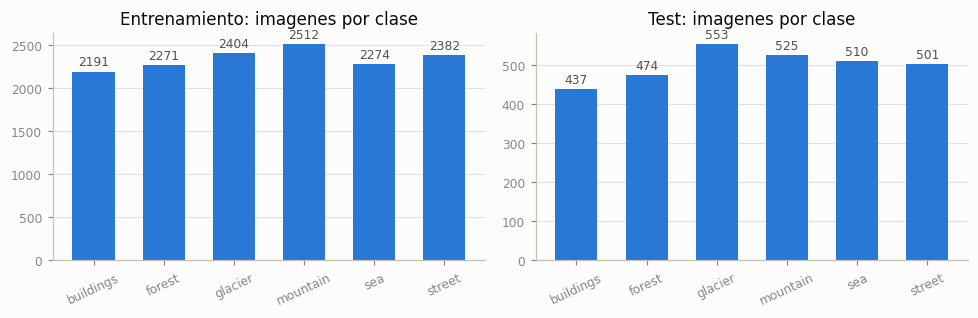

Ratio clase mayoritaria / minoritaria en entrenamiento: 1.15


In [10]:
# Distribucion de clases en entrenamiento y test
fig, ejes = plt.subplots(1, 2, figsize=(9, 3))
for eje, df, titulo in zip(ejes, [df_train_bruto, df_test_bruto], ['Entrenamiento', 'Test']):
    cuentas = df['clase'].value_counts().reindex(CLASES)
    barras = eje.bar(CLASES, cuentas.values, color=COLORES[0], width=0.6)
    eje.bar_label(barras, fontsize=8, color='#52514e', padding=2)
    eje.set_title(f'{titulo}: imagenes por clase')
    eje.grid(axis='x', visible=False)
    eje.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

cuentas = df_train_bruto['clase'].value_counts()
print('Ratio clase mayoritaria / minoritaria en entrenamiento: {:.2f}'.format(
    cuentas.max() / cuentas.min()))

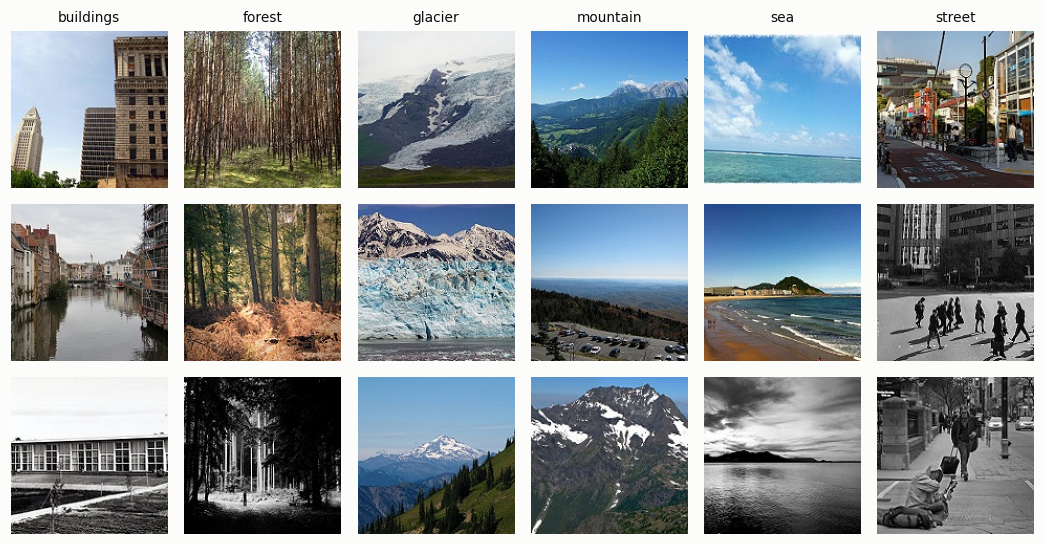

In [11]:
# Ejemplos aleatorios de cada clase
filas_muestra = 3
fig, ejes = plt.subplots(filas_muestra, NUM_CLASES,
                         figsize=(1.6 * NUM_CLASES, 1.7 * filas_muestra))
for j, clase in enumerate(CLASES):
    muestra = df_train_bruto[(df_train_bruto['clase'] == clase) &
                             df_train_bruto['valida']].sample(filas_muestra, random_state=SEED)
    for i, ruta in enumerate(muestra['ruta']):
        ejes[i, j].imshow(Image.open(ruta).convert('RGB'))
        ejes[i, j].axis('off')
        if i == 0:
            ejes[i, j].set_title(clase, fontsize=9)
plt.tight_layout()
plt.show()

In [12]:
# Control de calidad: duplicados exactos y fugas entre particiones
hash_test = set(df_test_bruto['hash'])
es_fuga = df_train_bruto['hash'].isin(hash_test) & df_train_bruto['valida']
es_dup = df_train_bruto['hash'].duplicated(keep='first') & df_train_bruto['valida']
etiquetas_por_hash = df_train_bruto[df_train_bruto['valida']].groupby('hash')['clase'].nunique()

print('Train repetidas tambien en test (fuga):', int(es_fuga.sum()))
print('Duplicados exactos dentro de train:    ', int(es_dup.sum()))
print('Hashes de train con etiquetas distintas:', int((etiquetas_por_hash > 1).sum()))

Train repetidas tambien en test (fuga): 3
Duplicados exactos dentro de train:     15
Hashes de train con etiquetas distintas: 10


### Análisis de los datos

* **Tamaño y clases:** El conjunto tiene 14.034 imágenes de entrenamiento y 3.000 de test en 6 clases. Es volumen suficiente para entrenar una CNN desde cero y comparar de forma justa ambas estrategias.
* **Equilibrio:** La relación entre la clase mayoritaria y la minoritaria es de solo 1,15, así que el conjunto está prácticamente equilibrado. Por eso la *accuracy* es una métrica representativa, y se complementa con el F1 *macro* y el F1 por clase. No hace falta ponderar clases ni sobremuestrear.
* **Dimensiones:** El 99,68 % de las imágenes mide 150x150. Las demás (32 tamaños distintos en total) tienen 150 px de ancho y algo menos de alto, así que redimensionarlas todas a 150x150 apenas introduce distorsión. Todas están en modo RGB y no hay archivos corruptos, aunque algunas fotografías son en blanco y negro, como se ve en las muestras.
* **Calidad:** Se han detectado 3 imágenes de entrenamiento repetidas en test, que se eliminan para evitar fuga de información, y 15 duplicados exactos dentro de entrenamiento. Además, 10 imágenes idénticas aparecen con etiquetas distintas, lo que demuestra que el conjunto contiene **ruido de etiquetado**. Eso fija un techo de *accuracy* inferior al 100 %.
* **Dificultad esperada:** En las muestras, *glacier* y *mountain* comparten nieve, roca y cielo, y *buildings* y *street* comparten fachadas. Son los pares que previsiblemente concentrarán los errores, mientras que *forest* es la clase visualmente más homogénea.

## 4. Acondicionamiento y preprocesamiento

Decisiones adoptadas:

* **Limpieza:** Se eliminan de entrenamiento los archivos corruptos, los duplicados internos y las imágenes también presentes en test, para evitar fugas de información.
* **Partición:** Se reserva un 15 % de entrenamiento como validación de forma estratificada, respetando la proporción de clases. Test permanece intacto.
* **Tamaño:** Todas las imágenes se llevan a 150x150, el tamaño nativo de casi todo el conjunto.
* **Normalización:** Se realiza dentro de cada modelo: [0, 1] en las CNN propias y [-1, 1] en las preentrenadas, que es la escala que esperan MobileNetV2, ResNet50V2 y Xception. Así, el preprocesado queda integrado en la red y no puede aplicarse de forma incorrecta.
* **Etiquetas:** Enteros con pérdida `sparse_categorical_crossentropy`.
* **Rendimiento:** Las imágenes se decodifican una vez y se guardan en memoria como `uint8`, lo que acelera las épocas y reduce el consumo de RAM.

In [13]:
df_train = df_train_bruto[df_train_bruto['valida'] & ~es_fuga & ~es_dup].copy()
df_test = df_test_bruto[df_test_bruto['valida']].copy()
df_train['y'] = df_train['clase'].map(CLASE_A_ID)
df_test['y'] = df_test['clase'].map(CLASE_A_ID)

df_tr, df_val = train_test_split(df_train, test_size=VAL_FRAC,
                                 stratify=df_train['y'], random_state=SEED)
df_test = df_test.reset_index(drop=True)
y_test = df_test['y'].values
PARTICIONES = {'train': df_tr, 'val': df_val, 'test': df_test}

resumen_part = pd.DataFrame({k: v['clase'].value_counts().reindex(CLASES)
                             for k, v in PARTICIONES.items()})
resumen_part.loc['TOTAL'] = resumen_part.sum()
print(resumen_part.to_string())

           train   val  test
clase                       
buildings   1861   329   437
forest      1929   340   474
glacier     2043   361   553
mountain    2129   376   525
sea         1931   341   510
street      2020   356   501
TOTAL      11913  2103  3000


In [14]:
def cargar(ruta, etiqueta):
    img = tf.io.read_file(ruta)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(tf.clip_by_value(tf.round(img), 0, 255), tf.uint8)
    img.set_shape((IMG_SIZE, IMG_SIZE, 3))
    return img, etiqueta


def _a_float(x, y):
    return tf.cast(x, tf.float32), y

# La cache en uint8 se comparte entre experimentos y tamanos de batch.
CACHE = {
    k: tf.data.Dataset.from_tensor_slices((v['ruta'].values, v['y'].values))
        .map(cargar, num_parallel_calls=tf.data.AUTOTUNE).cache()
    for k, v in PARTICIONES.items()
}


def lote(particion, batch=BATCH):
    ds = CACHE[particion]
    if particion == 'train':
        ds = ds.shuffle(len(df_tr), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch).map(_a_float, tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)


x_lote, y_lote = next(iter(lote('train')))
print('Forma del lote:', x_lote.shape, '| Rango:',
      float(tf.reduce_min(x_lote)), '-', float(tf.reduce_max(x_lote)))

Forma del lote: (32, 150, 150, 3) | Rango: 0.0 - 255.0


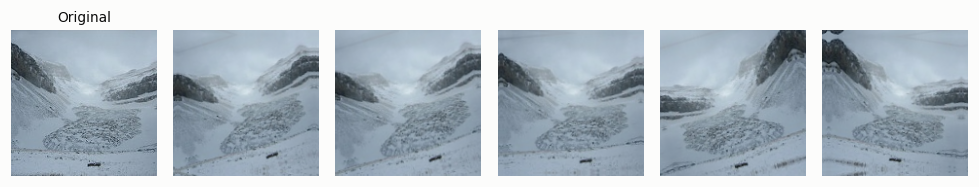

In [15]:
# Data augmentation: dentro del modelo para ejecutarse en GPU y solo al entrenar.
# No se usa volteo vertical ni giros grandes: una escena invertida no es realista.
def crear_aumento():
    return keras.Sequential([
        layers.RandomFlip('horizontal'),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.1),
        layers.RandomContrast(0.1),
    ], name='aumento')

muestra = tf.cast(x_lote[:1], tf.float32)
aumento = crear_aumento()
fig, ejes = plt.subplots(1, 6, figsize=(9, 1.7))
ejes[0].imshow(muestra[0].numpy().astype('uint8'))
ejes[0].set_title('Original', fontsize=9)
ejes[0].axis('off')
for eje in ejes[1:]:
    eje.imshow(np.clip(aumento(muestra, training=True)[0].numpy(), 0, 255).astype('uint8'))
    eje.axis('off')
plt.tight_layout()
plt.show()

## 5. Herramientas comunes de experimentación

Todos los experimentos utilizan el mismo procedimiento para que las comparaciones sean justas:

* Misma semilla y mismas particiones.
* `EarlyStopping` sobre `val_accuracy` y restauración de los pesos de la mejor época mediante `ModelCheckpoint`.
* Registro automático de métricas, tiempo y número de parámetros.
* Regla de decisión común: una variante sustituye al modelo vigente solo si supera su `val_accuracy` en al menos 0,3 puntos porcentuales. Una mejora menor se considera compatible con el ruido del entrenamiento, por lo que se mantiene la opción anterior.

La *accuracy* se usa como criterio porque la pérdida incluye la penalización L2 en los modelos regularizados y no sería directamente comparable. El **gap** (*accuracy* de entrenamiento menos validación en la mejor época) se usa como indicador de sobreajuste.

In [16]:
RESULTADOS = {}
ESPEC = {}


def ruta_pesos(nombre):
    return os.path.join(DIR_EXP, f'{nombre}.weights.h5')


def crear_optimizador(tipo, lr):
    if tipo == 'adam':
        return optimizers.Adam(lr)
    if tipo == 'sgd':
        return optimizers.SGD(lr, momentum=0.9, nesterov=True)
    raise ValueError(tipo)


def imprimir_historial(reg):
    h = reg['historial']
    for i in range(len(h['loss'])):
        print(f"Epoca {i + 1:02d} - acc {h['accuracy'][i]:.4f} - loss {h['loss'][i]:.4f}"
              f" - val_acc {h['val_accuracy'][i]:.4f} - val_loss {h['val_loss'][i]:.4f}")


def entrenar(nombre, crear_modelo, estrategia, opt='adam', lr=1e-3, batch=BATCH,
             epocas=EPOCAS_SCRATCH, paciencia=PACIENCIA, rlrop=False, padre=None):
    """Entrena un experimento, guarda sus mejores pesos y registra sus metricas."""
    ruta_json = os.path.join(DIR_EXP, f'{nombre}.json')
    if REANUDAR and os.path.exists(ruta_json) and os.path.exists(ruta_pesos(nombre)):
        with open(ruta_json) as f:
            reg = json.load(f)
        RESULTADOS[nombre] = reg
        print(f'[{nombre}] recuperado de una ejecucion anterior guardada en Drive')
        imprimir_historial(reg)
        return reg

    keras.backend.clear_session()
    gc.collect()
    keras.utils.set_random_seed(SEED)
    modelo = crear_modelo()
    modelo.compile(optimizer=crear_optimizador(opt, lr),
                   loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    entrenables = sum(int(np.prod(v.shape)) for v in modelo.trainable_weights)
    print(f'\n=== {nombre} | parametros: {modelo.count_params():,}'
          f' (entrenables {entrenables:,}) | {opt} lr={lr} batch={batch}')

    tmp = os.path.join(tempfile.gettempdir(), f'{nombre}.weights.h5')
    llamadas = [
        keras.callbacks.ModelCheckpoint(tmp, monitor='val_accuracy', mode='max',
                                        save_best_only=True, save_weights_only=True),
        keras.callbacks.EarlyStopping(monitor='val_accuracy', mode='max',
                                      patience=paciencia),
    ]
    if rlrop:
        llamadas.append(keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6))

    inicio = time.time()
    hist = modelo.fit(lote('train', batch), validation_data=lote('val', batch),
                      epochs=epocas, callbacks=llamadas, verbose=2)
    duracion = time.time() - inicio

    historial = {k: [float(x) for x in v] for k, v in hist.history.items()}
    mejor = int(np.argmax(historial['val_accuracy']))
    reg = {
        'nombre': nombre, 'estrategia': estrategia, 'padre': padre,
        'val_acc': historial['val_accuracy'][mejor],
        'val_loss': historial['val_loss'][mejor],
        'train_acc': historial['accuracy'][mejor],
        'gap': historial['accuracy'][mejor] - historial['val_accuracy'][mejor],
        'mejor_epoca': mejor + 1, 'epocas': len(historial['loss']),
        'tiempo_s': duracion, 'params': int(modelo.count_params()),
        'entrenables': entrenables, 'historial': historial,
    }
    shutil.copy(tmp, ruta_pesos(nombre))
    with open(ruta_json, 'w') as f:
        json.dump(reg, f)
    RESULTADOS[nombre] = reg
    del modelo
    return reg


def val(nombre):
    return RESULTADOS[nombre]['val_acc']


def diagnostico(r):
    if r['gap'] > 0.08:
        return 'sobreajuste'
    if r['gap'] > 0.03:
        return 'sobreaj. leve'
    if r['train_acc'] < 0.80:
        return 'subajuste'
    return 'ajustado'


def mostrar_tabla(nombres):
    filas = []
    for n in nombres:
        r = RESULTADOS[n]
        filas.append({'experimento': n, 'val_acc': round(r['val_acc'], 4),
                      'train_acc': round(r['train_acc'], 4), 'gap': round(r['gap'], 4),
                      'ep_mejor': r['mejor_epoca'], 'ep_tot': r['epocas'],
                      'min': round(r['tiempo_s'] / 60, 1),
                      'param_k': round(r['params'] / 1000),
                      'estado': diagnostico(r)})
    print(pd.DataFrame(filas).to_string(index=False))


def mostrar_curvas(nombres, titulo):
    """Val accuracy, val loss y gap por epoca, en una misma escala por panel."""
    fig, ejes = plt.subplots(1, 3, figsize=(10.5, 3.2))
    for i, n in enumerate(nombres):
        h = RESULTADOS[n]['historial']
        x = np.arange(1, len(h['loss']) + 1)
        c = COLORES[i]
        ejes[0].plot(x, h['val_accuracy'], color=c, label=n)
        ejes[1].plot(x, h['val_loss'], color=c)
        ejes[2].plot(x, np.array(h['accuracy']) - np.array(h['val_accuracy']), color=c)
    ejes[0].set_title('Accuracy de validacion')
    ejes[1].set_title('Perdida de validacion')
    ejes[2].set_title('Gap (train - val accuracy)')
    ejes[2].axhline(0, color='#c3c2b7', linewidth=1)
    for eje in ejes:
        eje.set_xlabel('Epoca')
    fig.suptitle(titulo, fontsize=12, color='#0b0b0b')
    fig.legend(loc='lower center', ncol=min(4, len(nombres)), bbox_to_anchor=(0.5, -0.12))
    plt.tight_layout()
    plt.show()


def mostrar_train_val(nombre):
    """Curvas de entrenamiento y validacion de un unico experimento."""
    h = RESULTADOS[nombre]['historial']
    x = np.arange(1, len(h['loss']) + 1)
    mejor = RESULTADOS[nombre]['mejor_epoca']
    fig, ejes = plt.subplots(1, 2, figsize=(8.5, 3))
    for eje, clave, titulo in zip(ejes, ['accuracy', 'loss'], ['Accuracy', 'Perdida']):
        eje.plot(x, h[clave], color=COLORES[0], linestyle='--', label='entrenamiento')
        eje.plot(x, h['val_' + clave], color=COLORES[1], label='validacion')
        eje.axvline(mejor, color='#898781', linewidth=1, linestyle=':')
        eje.set_title(f'{titulo} - {nombre}')
        eje.set_xlabel('Epoca')
        eje.legend()
    plt.tight_layout()
    plt.show()


def decidir(actual, candidatos, umbral=UMBRAL):
    """Adopta el mejor candidato solo si supera al modelo vigente por el umbral."""
    mejor = max(candidatos, key=val)
    mejora = val(mejor) - val(actual)
    elegido = mejor if mejora >= umbral else actual
    verbo = 'SE ADOPTA' if elegido == mejor else 'SE MANTIENE EL VIGENTE; descartado'
    print(f'\nDecision: vigente {actual} ({val(actual):.4f}) | mejor variante {mejor} '
          f'({val(mejor):.4f}) | mejora {mejora:+.4f} -> {verbo}: {mejor}')
    print('Modelo vigente tras la etapa:', elegido)
    return elegido

## 6. Estrategia 1: CNN desde cero

El desarrollo sigue una **experimentación progresiva**: se construye primero un modelo sencillo y se modifica un grupo de decisiones cada vez. Cada etapa parte del modelo ganador de la anterior.

| Etapa | Pregunta |
|---|---|
| 6.1 | ¿Aprende un modelo base y cuál es su comportamiento? |
| 6.2 | ¿Mejora con más profundidad? |
| 6.3 | ¿Influyen el kernel, los bloques de doble convolución o la activación? |
| 6.4 | ¿Es mejor `Flatten` o *Global Average Pooling* en el cierre? |
| 6.5 | ¿Qué técnicas de regularización reducen el sobreajuste? |
| 6.6 | ¿Qué optimizador y tasa de aprendizaje funcionan mejor? |
| 6.7 | ¿Afecta el tamaño del batch? |

In [17]:
def construir_cnn(filtros, kernel=3, convs=1, activacion='relu', cierre='flatten',
                  dense=128, drop_conv=0.0, drop_dense=0.0, l2_w=0.0, bn=False, aug=False):
    reg = regularizers.l2(l2_w) if l2_w else None
    entrada = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = crear_aumento()(entrada) if aug else entrada
    x = layers.Rescaling(1.0 / 255)(x)
    for f in filtros:
        for _ in range(convs):
            x = layers.Conv2D(f, kernel, padding='same', use_bias=not bn,
                              kernel_regularizer=reg)(x)
            if bn:
                x = layers.BatchNormalization()(x)
            x = layers.Activation(activacion)(x)
        x = layers.MaxPooling2D()(x)
        if drop_conv:
            x = layers.Dropout(drop_conv)(x)
    x = layers.Flatten()(x) if cierre == 'flatten' else layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense, use_bias=not bn, kernel_regularizer=reg)(x)
    if bn:
        x = layers.BatchNormalization()(x)
    x = layers.Activation(activacion)(x)
    if drop_dense:
        x = layers.Dropout(drop_dense)(x)
    salida = layers.Dense(NUM_CLASES, activation='softmax', kernel_regularizer=reg)(x)
    return keras.Model(entrada, salida)


CLAVES_ENT = ('opt', 'lr', 'batch', 'rlrop')


def exp_cnn(nombre, espec):
    ESPEC[nombre] = espec
    cfg = {k: v for k, v in espec.items() if k not in CLAVES_ENT}
    ent = {k: espec[k] for k in CLAVES_ENT}
    return entrenar(nombre, lambda: construir_cnn(**cfg), 'scratch', **ent)


def etapa(actual, variantes, titulo):
    """Entrena variantes del modelo vigente, las compara y decide."""
    for nombre, cambios in variantes.items():
        exp_cnn(nombre, {**ESPEC[actual], **cambios})
    nombres = [actual] + list(variantes)
    print()
    mostrar_tabla(nombres)
    mostrar_curvas(nombres, titulo)
    return decidir(actual, list(variantes))

### 6.1 Modelo base

Se parte de tres bloques convolucionales, sin ninguna regularización ni *data augmentation*. Sirve como referencia para detectar si la red es capaz de aprender y qué problema aparece primero.


=== F0_base | parametros: 5,402,566 (entrenables 5,402,566) | adam lr=0.001 batch=32
Epoch 1/40
373/373 - 37s - 98ms/step - accuracy: 0.6534 - loss: 0.9013 - val_accuracy: 0.7561 - val_loss: 0.6883
Epoch 2/40
373/373 - 10s - 28ms/step - accuracy: 0.7816 - loss: 0.5850 - val_accuracy: 0.7836 - val_loss: 0.5923
Epoch 3/40
373/373 - 20s - 55ms/step - accuracy: 0.8430 - loss: 0.4300 - val_accuracy: 0.8136 - val_loss: 0.5343
Epoch 4/40
373/373 - 10s - 27ms/step - accuracy: 0.8963 - loss: 0.2911 - val_accuracy: 0.7713 - val_loss: 0.6922
Epoch 5/40
373/373 - 10s - 28ms/step - accuracy: 0.9328 - loss: 0.1873 - val_accuracy: 0.8203 - val_loss: 0.5872
Epoch 6/40
373/373 - 10s - 27ms/step - accuracy: 0.9594 - loss: 0.1135 - val_accuracy: 0.8207 - val_loss: 0.7733
Epoch 7/40
373/373 - 10s - 28ms/step - accuracy: 0.9741 - loss: 0.0796 - val_accuracy: 0.8036 - val_loss: 0.9430
Epoch 8/40
373/373 - 10s - 28ms/step - accuracy: 0.9826 - loss: 0.0572 - val_accuracy: 0.8150 - val_loss: 0.9559
Epoch 9/40

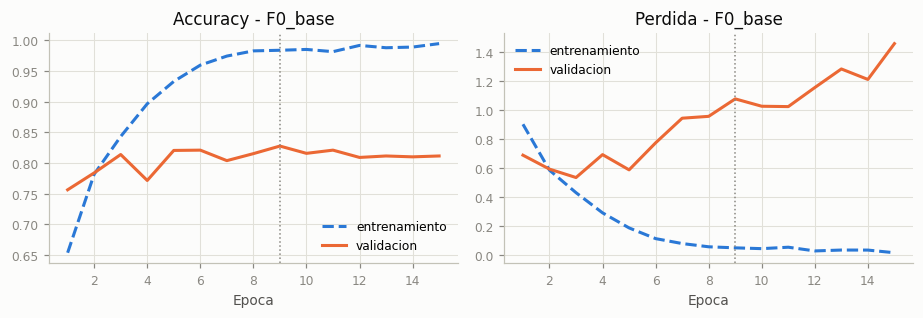

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 150, 150, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     5,308,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,402,566 (20.61 MB)

 Trainable params: 5,402,566 (20.61 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
espec_base = dict(filtros=(32, 64, 128), kernel=3, convs=1, activacion='relu',
                  cierre='flatten', dense=128, drop_conv=0.0, drop_dense=0.0,
                  l2_w=0.0, bn=False, aug=False,
                  opt='adam', lr=1e-3, batch=BATCH, rlrop=False)
exp_cnn('F0_base', espec_base)
mostrar_tabla(['F0_base'])
mostrar_train_val('F0_base')
construir_cnn(**{k: v for k, v in espec_base.items() if k not in CLAVES_ENT}).summary()
vigente = 'F0_base'

**Análisis del modelo base.** La red aprende rápidamente patrones relevantes: alcanza un 82,7 % de *accuracy* de validación, muy por encima del 16,7 % de un clasificador aleatorio. Sin embargo, presenta un **sobreajuste severo**:

* La *accuracy* de entrenamiento llega al 98,4 %, con un gap de 15,6 puntos.
* La pérdida de validación es mínima en la época 3 (0,53) y después crece hasta 1,46 en la época 15, mientras la de entrenamiento sigue bajando. El modelo memoriza el conjunto de entrenamiento y se vuelve excesivamente confiado en sus errores.

La causa principal es estructural. El `Flatten` sobre un mapa de 18x18x128 alimenta una capa densa con 5,3 de los 5,4 millones de parámetros del modelo. Las siguientes etapas buscan reducir esa capacidad sobrante, primero mediante la arquitectura y después mediante regularización explícita.

### 6.2 Profundidad

Más bloques aumentan la capacidad y el campo receptivo, pero también el riesgo de sobreajuste. Al añadir *pooling* se reduce el mapa final y, con `Flatten`, el número de parámetros.


=== F1_4bloques | parametros: 3,043,526 (entrenables 3,043,526) | adam lr=0.001 batch=32
Epoch 1/40
373/373 - 24s - 64ms/step - accuracy: 0.6107 - loss: 0.9778 - val_accuracy: 0.6510 - val_loss: 0.8698
Epoch 2/40
373/373 - 12s - 31ms/step - accuracy: 0.7520 - loss: 0.6601 - val_accuracy: 0.7737 - val_loss: 0.6259
Epoch 3/40
373/373 - 12s - 31ms/step - accuracy: 0.8113 - loss: 0.5222 - val_accuracy: 0.8236 - val_loss: 0.5005
Epoch 4/40
373/373 - 12s - 31ms/step - accuracy: 0.8439 - loss: 0.4273 - val_accuracy: 0.8003 - val_loss: 0.5501
Epoch 5/40
373/373 - 12s - 31ms/step - accuracy: 0.8746 - loss: 0.3473 - val_accuracy: 0.8426 - val_loss: 0.4537
Epoch 6/40
373/373 - 12s - 33ms/step - accuracy: 0.8979 - loss: 0.2801 - val_accuracy: 0.8469 - val_loss: 0.5044
Epoch 7/40
373/373 - 11s - 31ms/step - accuracy: 0.9271 - loss: 0.2005 - val_accuracy: 0.8336 - val_loss: 0.5959
Epoch 8/40
373/373 - 11s - 31ms/step - accuracy: 0.9431 - loss: 0.1616 - val_accuracy: 0.8321 - val_loss: 0.6320
Epoch 

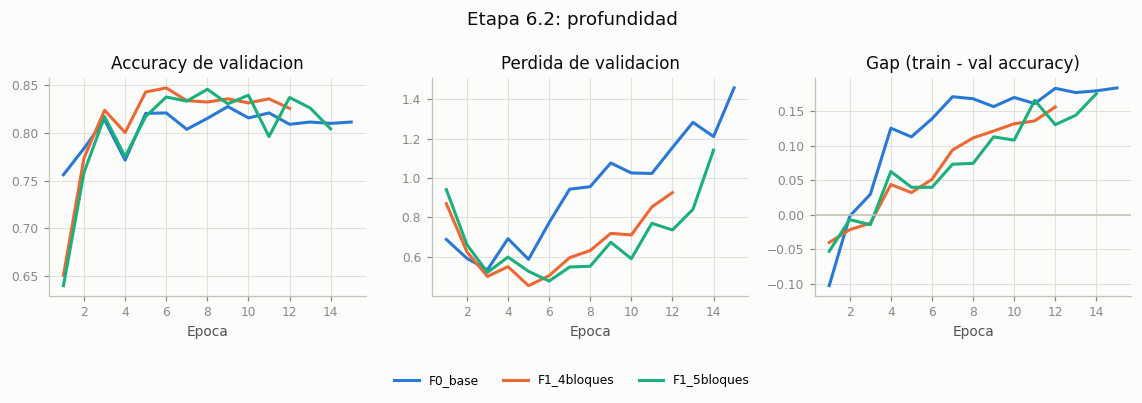


Decision: vigente F0_base (0.8274) | mejor variante F1_4bloques (0.8469) | mejora +0.0195 -> SE ADOPTA: F1_4bloques
Modelo vigente tras la etapa: F1_4bloques


In [19]:
vigente = etapa(vigente, {
    'F1_4bloques': {'filtros': (32, 64, 128, 256)},
    'F1_5bloques': {'filtros': (32, 64, 128, 256, 512)},
}, 'Etapa 6.2: profundidad')

**Análisis de la profundidad:** Añadir un cuarto bloque mejora la validación en 1,95 puntos (del 82,7 % al 84,7 %) y reduce el gap del 15,6 % al 5,1 %. Además, baja los parámetros de 5,4 a 3,0 millones, porque el *pooling* adicional reduce el mapa que llega a `Flatten`. Por tanto, más profundidad aporta un campo receptivo mayor con menos parámetros densos.

El quinto bloque no mejora (84,6 %) y aumenta de nuevo el gap (7,4 %), lo que indica que la ganancia de profundidad se satura con imágenes de 150x150. **Se adopta la red de 4 bloques**, la opción más sencilla entre las dos de rendimiento equivalente.

### 6.3 Kernel, doble convolución y activación

Se evalúa un kernel de 5x5 (más contexto, más parámetros), dos convoluciones por bloque antes de reducir la resolución (más no linealidad) y la activación ELU, que evita neuronas inactivas al permitir salidas negativas.


=== F2_kernel5 | parametros: 3,733,190 (entrenables 3,733,190) | adam lr=0.001 batch=32
Epoch 1/40
373/373 - 43s - 114ms/step - accuracy: 0.5734 - loss: 1.0532 - val_accuracy: 0.6686 - val_loss: 0.8317
Epoch 2/40
373/373 - 57s - 153ms/step - accuracy: 0.7036 - loss: 0.7706 - val_accuracy: 0.7228 - val_loss: 0.7547
Epoch 3/40
373/373 - 16s - 44ms/step - accuracy: 0.7768 - loss: 0.6081 - val_accuracy: 0.7898 - val_loss: 0.5845
Epoch 4/40
373/373 - 16s - 44ms/step - accuracy: 0.8229 - loss: 0.4835 - val_accuracy: 0.7965 - val_loss: 0.5909
Epoch 5/40
373/373 - 17s - 44ms/step - accuracy: 0.8564 - loss: 0.3899 - val_accuracy: 0.7998 - val_loss: 0.5902
Epoch 6/40
373/373 - 16s - 43ms/step - accuracy: 0.8912 - loss: 0.2955 - val_accuracy: 0.7927 - val_loss: 0.6700
Epoch 7/40
373/373 - 16s - 43ms/step - accuracy: 0.9237 - loss: 0.2104 - val_accuracy: 0.8065 - val_loss: 0.8285
Epoch 8/40
373/373 - 16s - 43ms/step - accuracy: 0.9433 - loss: 0.1608 - val_accuracy: 0.8326 - val_loss: 0.6972
Epoch

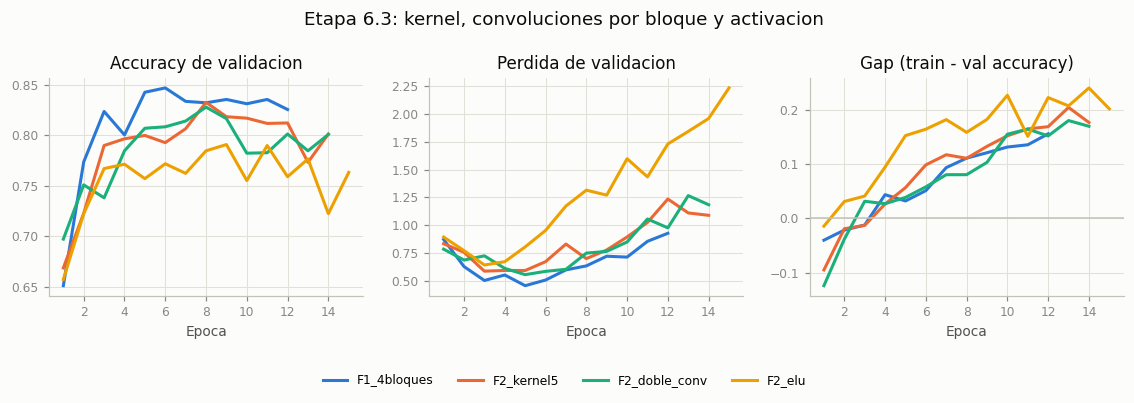


Decision: vigente F1_4bloques (0.8469) | mejor variante F2_kernel5 (0.8326) | mejora -0.0143 -> SE MANTIENE EL VIGENTE; descartado: F2_kernel5
Modelo vigente tras la etapa: F1_4bloques


In [20]:
vigente = etapa(vigente, {
    'F2_kernel5': {'kernel': 5},
    'F2_doble_conv': {'convs': 2},
    'F2_elu': {'activacion': 'elu'},
}, 'Etapa 6.3: kernel, convoluciones por bloque y activacion')

**Análisis del kernel, la doble convolución y la activación:** Ninguna variante supera al modelo vigente, y todas aumentan el sobreajuste:

* **Kernel 5x5:** 83,3 % de validación y gap del 11,1 %. Añade un 23 % de parámetros sin beneficio, porque dos capas 3x3 sucesivas ya cubren un campo receptivo equivalente.
* **Doble convolución por bloque:** 82,8 % de validación. Es la variante más lenta (7,1 min) y aumenta la capacidad en un modelo que ya sobreajusta.
* **ELU:** es la peor (79,1 %), con un gap del 18,2 %. Sin otra regularización, converge más rápido hacia la memorización del conjunto.

Se mantienen los **kernels 3x3, una convolución por bloque y ReLU**. El experimento confirma que el problema no es la falta de capacidad, sino su exceso.

### 6.4 Capas finales

*Global Average Pooling* reduce drásticamente los parámetros respecto a `Flatten`, actuando como una regularización estructural. Se compara también una capa densa más pequeña.


=== F3_gap | parametros: 422,086 (entrenables 422,086) | adam lr=0.001 batch=32
Epoch 1/40
373/373 - 18s - 49ms/step - accuracy: 0.5277 - loss: 1.1134 - val_accuracy: 0.6890 - val_loss: 0.8264
Epoch 2/40
373/373 - 12s - 31ms/step - accuracy: 0.7068 - loss: 0.7737 - val_accuracy: 0.7351 - val_loss: 0.7261
Epoch 3/40
373/373 - 12s - 31ms/step - accuracy: 0.7468 - loss: 0.6745 - val_accuracy: 0.7832 - val_loss: 0.6012
Epoch 4/40
373/373 - 11s - 31ms/step - accuracy: 0.7739 - loss: 0.6083 - val_accuracy: 0.7537 - val_loss: 0.6464
Epoch 5/40
373/373 - 12s - 32ms/step - accuracy: 0.8039 - loss: 0.5377 - val_accuracy: 0.8169 - val_loss: 0.5048
Epoch 6/40
373/373 - 11s - 30ms/step - accuracy: 0.8196 - loss: 0.4958 - val_accuracy: 0.7908 - val_loss: 0.6112
Epoch 7/40
373/373 - 12s - 31ms/step - accuracy: 0.8384 - loss: 0.4517 - val_accuracy: 0.8231 - val_loss: 0.5134
Epoch 8/40
373/373 - 12s - 31ms/step - accuracy: 0.8463 - loss: 0.4289 - val_accuracy: 0.8312 - val_loss: 0.4813
Epoch 9/40
373/

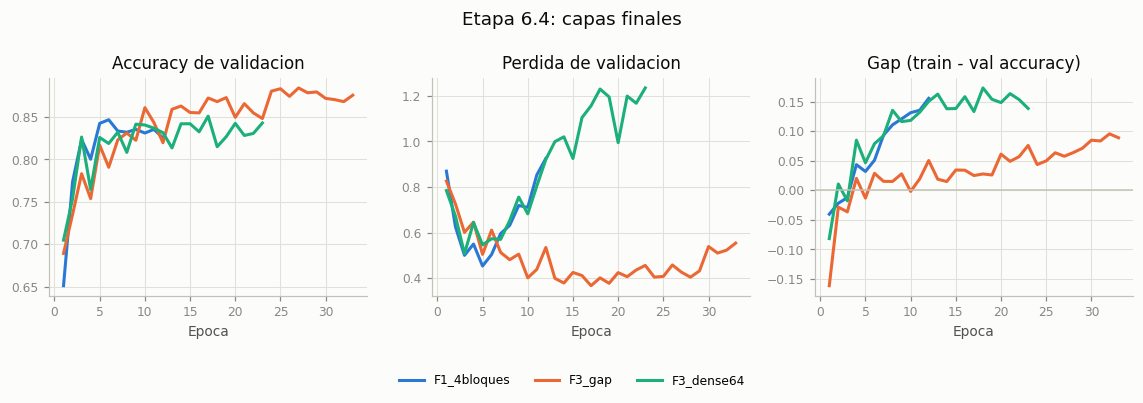


Decision: vigente F1_4bloques (0.8469) | mejor variante F3_gap (0.8845) | mejora +0.0376 -> SE ADOPTA: F3_gap
Modelo vigente tras la etapa: F3_gap


In [21]:
vigente = etapa(vigente, {
    'F3_gap': {'cierre': 'gap'},
    'F3_dense64': {'dense': 64},
}, 'Etapa 6.4: capas finales')

**Análisis de las capas finales:** *Global Average Pooling* es el cambio con mayor impacto de toda la estrategia 1:

* Reduce los parámetros de 3,04 millones a 422.000 (un 86 % menos).
* Aumenta la validación en 3,8 puntos, hasta el 88,5 %.

Al promediar cada mapa de activación, GAP elimina la mayor parte de los pesos densos, que eran la vía principal de memorización. Además, obliga a que cada filtro represente un concepto presente en toda la imagen, algo coherente con escenas donde la clase depende del contenido global. Como el modelo aprende más despacio pero sin estancarse, la mejor época pasa de la 6 a la 27.

En cambio, reducir la capa densa a 64 neuronas manteniendo `Flatten` apenas mejora (85,1 %) y conserva un gap alto (13,3 %), porque el cuello de botella de parámetros está en la conexión con `Flatten`, no en el tamaño de la capa. **Se adopta GAP.**

### 6.5 Regularización

Cada técnica se evalúa primero de forma **aislada** sobre el modelo vigente, para conocer su efecto individual:

| Técnica | Problema que aborda |
|---|---|
| *Dropout* | Coadaptación de neuronas |
| *Weight regularization* (L2) | Pesos excesivamente grandes |
| *Batch normalization* | Inestabilidad del entrenamiento; además, efecto regularizador leve |
| *Data augmentation* | Escasa variabilidad del conjunto de entrenamiento |

Después se combinan únicamente las técnicas que han mejorado la validación por separado.


=== F4_dropout | parametros: 422,086 (entrenables 422,086) | adam lr=0.001 batch=32
Epoch 1/40
373/373 - 30s - 79ms/step - accuracy: 0.4529 - loss: 1.2612 - val_accuracy: 0.5844 - val_loss: 1.0034
Epoch 2/40
373/373 - 25s - 67ms/step - accuracy: 0.6062 - loss: 0.9440 - val_accuracy: 0.6942 - val_loss: 0.8022
Epoch 3/40
373/373 - 12s - 32ms/step - accuracy: 0.7011 - loss: 0.7984 - val_accuracy: 0.7589 - val_loss: 0.6620
Epoch 4/40
373/373 - 12s - 32ms/step - accuracy: 0.7443 - loss: 0.7042 - val_accuracy: 0.7846 - val_loss: 0.5950
Epoch 5/40
373/373 - 12s - 33ms/step - accuracy: 0.7730 - loss: 0.6340 - val_accuracy: 0.7846 - val_loss: 0.5720
Epoch 6/40
373/373 - 12s - 31ms/step - accuracy: 0.7891 - loss: 0.5817 - val_accuracy: 0.7722 - val_loss: 0.6175
Epoch 7/40
373/373 - 12s - 31ms/step - accuracy: 0.8080 - loss: 0.5380 - val_accuracy: 0.8374 - val_loss: 0.4626
Epoch 8/40
373/373 - 12s - 31ms/step - accuracy: 0.8213 - loss: 0.4975 - val_accuracy: 0.8355 - val_loss: 0.4564
Epoch 9/40


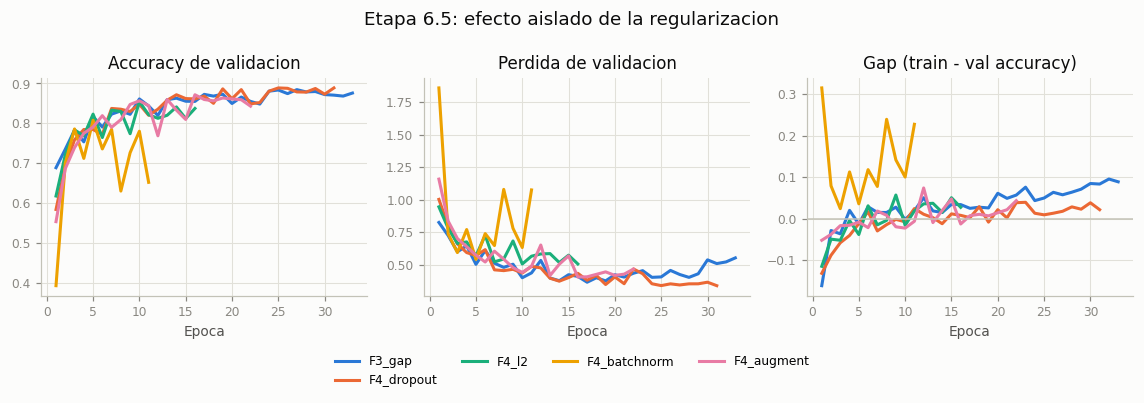


Tecnicas que mejoran la validacion por separado: ['F4_dropout']


In [22]:
TECNICAS = {
    'F4_dropout': {'drop_conv': 0.2, 'drop_dense': 0.5},
    'F4_l2': {'l2_w': 1e-4},
    'F4_batchnorm': {'bn': True},
    'F4_augment': {'aug': True},
}
for nombre, cambios in TECNICAS.items():
    exp_cnn(nombre, {**ESPEC[vigente], **cambios})

print()
mostrar_tabla([vigente] + list(TECNICAS))
mostrar_curvas([vigente] + list(TECNICAS), 'Etapa 6.5: efecto aislado de la regularizacion')

utiles = [n for n in TECNICAS if val(n) > val(vigente)]
print('\nTecnicas que mejoran la validacion por separado:', utiles)

In [23]:
# Combinacion guiada por el resultado anterior
candidatos = list(TECNICAS)
if len(utiles) >= 2:
    combinada = {}
    for n in utiles:
        combinada.update(TECNICAS[n])
    print('Se combina:', combinada)
    exp_cnn('F4_combinada', {**ESPEC[vigente], **combinada})
    candidatos.append('F4_combinada')
    mostrar_tabla([vigente, 'F4_combinada'])
    mostrar_train_val('F4_combinada')
else:
    print('Menos de dos tecnicas aportan mejora: no procede combinarlas.')

vigente = decidir(vigente, candidatos)

Menos de dos tecnicas aportan mejora: no procede combinarlas.

Decision: vigente F3_gap (0.8845) | mejor variante F4_dropout (0.8887) | mejora +0.0043 -> SE ADOPTA: F4_dropout
Modelo vigente tras la etapa: F4_dropout


**Análisis de la regularización:** El modelo de partida (GAP) tiene una validación del 88,5 % y un gap del 5,8 %, que aumenta al final del entrenamiento, como se ve en el tercer panel.

| Técnica | Val. acc. | Gap | Efecto observado |
|---|---|---|---|
| *Dropout* (0,2 conv. / 0,5 densa) | **88,9 %** | 0,9 % | Elimina prácticamente el sobreajuste y es la única técnica que mejora la validación |
| L2 (1e-4) | 85,5 % | -1,6 % | Penaliza en exceso: el modelo pasa a un leve **subajuste** (entrenamiento al 83,9 %) y se detiene en la época 16 |
| *Batch normalization* | 80,8 % | 3,6 % | Curvas de validación muy inestables, con oscilaciones de hasta 15 puntos entre épocas; la parada temprana ocurre en la época 11 |
| *Data augmentation* | 87,2 % | -1,3 % | Elimina el gap, pero en 22 épocas no alcanza al modelo sin aumento |

Todas las técnicas reducen el gap, así que cumplen su objetivo de **reducir el sobreajuste**, pero solo el *dropout* lo convierte en mejor generalización. *Batch normalization* acelera el ajuste inicial, pero con lotes de 32 y una tasa de 1e-3 introduce mucho ruido en las estadísticas de validación. Como solo una técnica mejora por separado, la regla definida no combina técnicas, y **se adopta el *dropout*** (+0,43 puntos y gap del 0,9 %).

**Limitación.** Las curvas de L2 y *data augmentation* aún mejoraban cuando las detuvo la parada temprana (paciencia 6). Con una paciencia mayor o una tasa de aprendizaje decreciente, probablemente rendirían mejor. Queda pendiente probar la combinación *dropout* + *data augmentation* con más épocas.

### 6.6 Optimizador y tasa de aprendizaje

Se evalúan una tasa de aprendizaje menor, SGD con momento de Nesterov y la reducción de la tasa cuando la validación se estanca.


=== F5_adam_3e-4 | parametros: 422,086 (entrenables 422,086) | adam lr=0.0003 batch=32
Epoch 1/40
373/373 - 26s - 69ms/step - accuracy: 0.4180 - loss: 1.3554 - val_accuracy: 0.5445 - val_loss: 1.1168
Epoch 2/40
373/373 - 13s - 34ms/step - accuracy: 0.5568 - loss: 1.0537 - val_accuracy: 0.5968 - val_loss: 0.9909
Epoch 3/40
373/373 - 12s - 32ms/step - accuracy: 0.6348 - loss: 0.9219 - val_accuracy: 0.6885 - val_loss: 0.8496
Epoch 4/40
373/373 - 12s - 32ms/step - accuracy: 0.6834 - loss: 0.8337 - val_accuracy: 0.7209 - val_loss: 0.7640
Epoch 5/40
373/373 - 12s - 32ms/step - accuracy: 0.7158 - loss: 0.7681 - val_accuracy: 0.7123 - val_loss: 0.7618
Epoch 6/40
373/373 - 12s - 32ms/step - accuracy: 0.7428 - loss: 0.7062 - val_accuracy: 0.7656 - val_loss: 0.6560
Epoch 7/40
373/373 - 12s - 32ms/step - accuracy: 0.7549 - loss: 0.6804 - val_accuracy: 0.7836 - val_loss: 0.6108
Epoch 8/40
373/373 - 12s - 32ms/step - accuracy: 0.7744 - loss: 0.6334 - val_accuracy: 0.7951 - val_loss: 0.5748
Epoch 9/

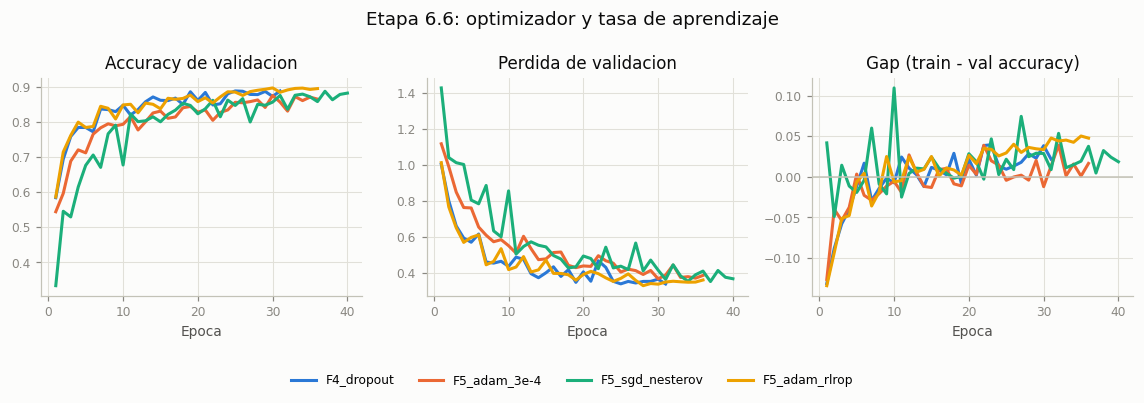


Decision: vigente F4_dropout (0.8887) | mejor variante F5_adam_rlrop (0.8973) | mejora +0.0086 -> SE ADOPTA: F5_adam_rlrop
Modelo vigente tras la etapa: F5_adam_rlrop


In [24]:
vigente = etapa(vigente, {
    'F5_adam_3e-4': {'lr': 3e-4},
    'F5_sgd_nesterov': {'opt': 'sgd', 'lr': 0.01},
    'F5_adam_rlrop': {'rlrop': True},
}, 'Etapa 6.6: optimizador y tasa de aprendizaje')

**Análisis del optimizador.**

* **Adam con `ReduceLROnPlateau`:** es la mejor opción, con un 89,7 % de validación (+0,86 puntos). Las reducciones de la tasa de aprendizaje permiten afinar los pesos cuando la pérdida de validación se estanca, y las curvas se suavizan claramente en las últimas épocas. A cambio, el gap sube del 0,9 % al 3,4 %, ya que el modelo se ajusta más al entrenamiento, aunque se mantiene en un nivel moderado.
* **SGD con momento de Nesterov:** consigue un rendimiento similar (88,8 %), pero su mejor época es la 37 de un máximo de 40, lo que confirma su convergencia más lenta. Podría mejorar con más épocas.
* **Adam con 3e-4:** también converge más despacio y obtiene un 87,6 %, con un ligero subajuste (gap -1,2 %).

**Se adopta Adam (1e-3) con `ReduceLROnPlateau`.**

### 6.7 Tamaño del batch


=== F6_batch16 | parametros: 422,086 (entrenables 422,086) | adam lr=0.001 batch=16
Epoch 1/40
745/745 - 39s - 53ms/step - accuracy: 0.4566 - loss: 1.2254 - val_accuracy: 0.5887 - val_loss: 0.9986 - learning_rate: 0.0010
Epoch 2/40
745/745 - 13s - 17ms/step - accuracy: 0.6023 - loss: 0.9506 - val_accuracy: 0.7104 - val_loss: 0.7658 - learning_rate: 0.0010
Epoch 3/40
745/745 - 13s - 17ms/step - accuracy: 0.7060 - loss: 0.7843 - val_accuracy: 0.7485 - val_loss: 0.6641 - learning_rate: 0.0010
Epoch 4/40
745/745 - 13s - 17ms/step - accuracy: 0.7579 - loss: 0.6665 - val_accuracy: 0.8065 - val_loss: 0.5601 - learning_rate: 0.0010
Epoch 5/40
745/745 - 13s - 18ms/step - accuracy: 0.7880 - loss: 0.5933 - val_accuracy: 0.8107 - val_loss: 0.5219 - learning_rate: 0.0010
Epoch 6/40
745/745 - 13s - 18ms/step - accuracy: 0.8015 - loss: 0.5471 - val_accuracy: 0.8041 - val_loss: 0.5429 - learning_rate: 0.0010
Epoch 7/40
745/745 - 13s - 17ms/step - accuracy: 0.8230 - loss: 0.5095 - val_accuracy: 0.7917

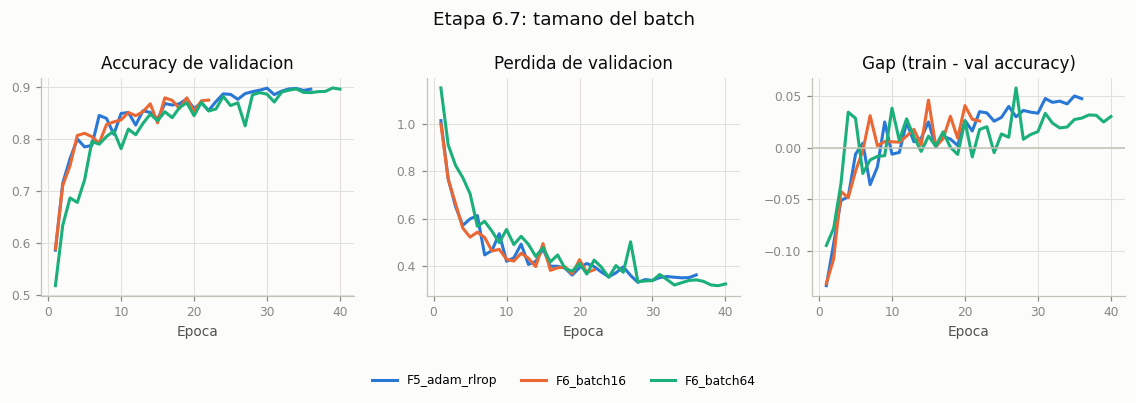


Decision: vigente F5_adam_rlrop (0.8973) | mejor variante F6_batch64 (0.8978) | mejora +0.0005 -> SE MANTIENE EL VIGENTE; descartado: F6_batch64
Modelo vigente tras la etapa: F5_adam_rlrop

Modelo seleccionado para la estrategia 1: F5_adam_rlrop
Especificacion: {'filtros': (32, 64, 128, 256), 'kernel': 3, 'convs': 1, 'activacion': 'relu', 'cierre': 'gap', 'dense': 128, 'drop_conv': 0.2, 'drop_dense': 0.5, 'l2_w': 0.0, 'bn': False, 'aug': False, 'opt': 'adam', 'lr': 0.001, 'batch': 32, 'rlrop': True}


In [25]:
vigente = etapa(vigente, {
    'F6_batch16': {'batch': 16},
    'F6_batch64': {'batch': 64},
}, 'Etapa 6.7: tamano del batch')

MEJOR_SCRATCH = vigente
print('\nModelo seleccionado para la estrategia 1:', MEJOR_SCRATCH)
print('Especificacion:', ESPEC[MEJOR_SCRATCH])

### 6.8 Evolución y modelo final de la estrategia 1

    experimento  val_acc  train_acc     gap  ep_mejor  ep_tot  min  param_k        estado
        F0_base   0.8274     0.9836  0.1562         9      15  3.4     5403   sobreajuste
    F1_4bloques   0.8469     0.8979  0.0510         6      12  2.6     3044 sobreaj. leve
    F1_5bloques   0.8455     0.9197  0.0742         8      14  3.5     2618 sobreaj. leve
     F2_kernel5   0.8326     0.9433  0.1106         8      14  4.9     3733   sobreajuste
  F2_doble_conv   0.8279     0.9083  0.0805         8      14  7.1     3827   sobreajuste
         F2_elu   0.7908     0.9732  0.1824         9      15  3.3     3044   sobreajuste
         F3_gap   0.8845     0.9422  0.0577        27      33  6.6      422 sobreaj. leve
     F3_dense64   0.8512     0.9846  0.1334        17      23  4.7     1716   sobreajuste
     F4_dropout   0.8887     0.8982  0.0094        25      31  6.7      422      ajustado
          F4_l2   0.8545     0.8387 -0.0158        10      16  3.4      422      ajustado
   F4_batc

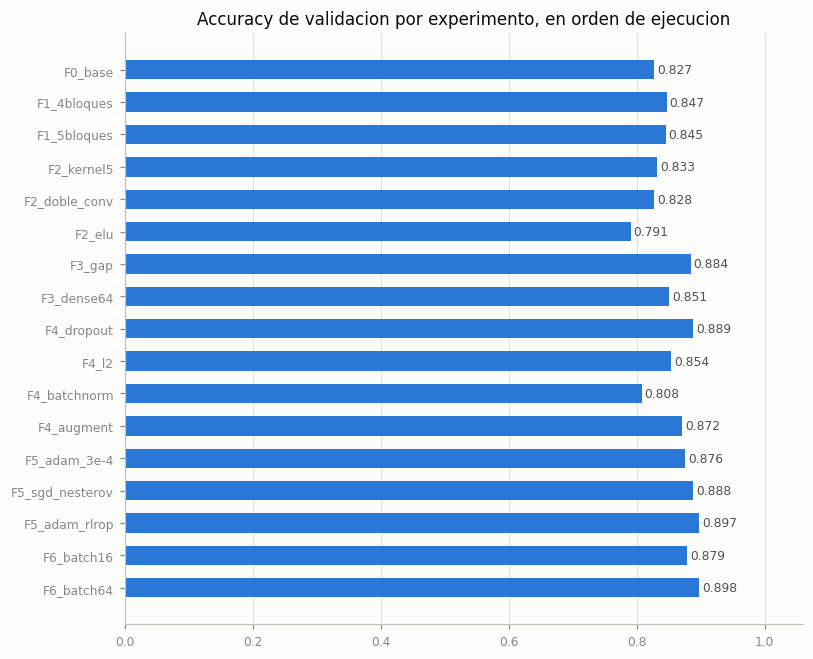

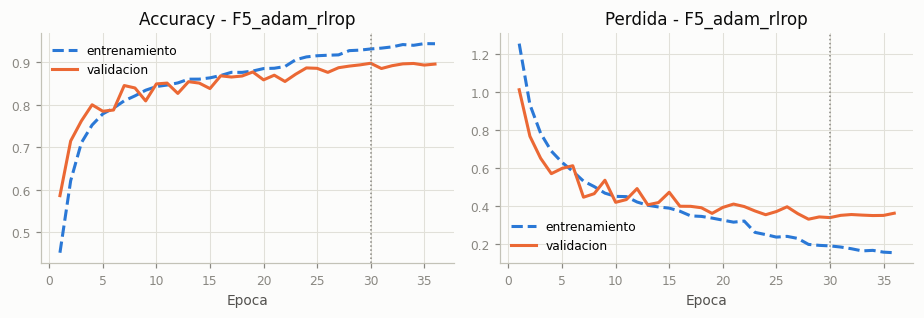

In [26]:
exp_scratch = [n for n, r in RESULTADOS.items() if r['estrategia'] == 'scratch']
mostrar_tabla(exp_scratch)

fig, eje = plt.subplots(figsize=(7.5, 0.3 * len(exp_scratch) + 1))
posiciones = np.arange(len(exp_scratch))[::-1]
valores = [val(n) for n in exp_scratch]
barras = eje.barh(posiciones, valores, color=COLORES[0], height=0.6)
eje.set_yticks(posiciones, exp_scratch)
eje.bar_label(barras, fmt='%.3f', fontsize=8, color='#52514e', padding=2)
eje.set_xlim(0, 1.06)
eje.grid(axis='y', visible=False)
eje.set_title('Accuracy de validacion por experimento, en orden de ejecucion')
plt.tight_layout()
plt.show()

mostrar_train_val(MEJOR_SCRATCH)

**Evolución de la estrategia 1.** La validación pasa del 82,7 % del modelo base al 89,7 % del modelo final, y el gap se reduce del 15,6 % al 3,4 %. Las mejoras proceden casi por completo de **reducir la capacidad sobrante y regularizar**:

| Decisión | Mejora en validación |
|---|---|
| Cuarto bloque convolucional | +1,95 puntos |
| *Global Average Pooling* | +3,76 puntos |
| *Dropout* | +0,43 puntos |
| `ReduceLROnPlateau` | +0,86 puntos |

Las decisiones que añadían capacidad (kernel 5x5, doble convolución) o inestabilidad (ELU, *batch normalization*) se descartaron con evidencia experimental. El tamaño de batch no cambia de forma relevante el resultado: con 64, la mejora es de solo +0,05 puntos, por debajo del umbral.

El **modelo final** tiene 4 bloques (32-64-128-256 filtros 3x3, ReLU y *max pooling*), GAP, una capa densa de 128 neuronas, *dropout* de 0,2 y 0,5, y Adam con `ReduceLROnPlateau`. Tiene solo **422.000 parámetros**, 13 veces menos que el modelo base. Sus curvas muestran una convergencia estable con un ligero sobreajuste al final, y los pesos guardados corresponden a la mejor época de validación (la 30).

## 7. Estrategia 2: redes preentrenadas

Se comparan tres arquitecturas con pesos de ImageNet y filosofías distintas:

| Arquitectura | Motivo |
|---|---|
| **MobileNetV2** | Muy ligera; convoluciones separables e *inverted residuals* |
| **ResNet50V2** | Referencia clásica con conexiones residuales |
| **Xception** | Convoluciones separables en profundidad, buena precisión con un tamaño moderado |

Todas esperan entradas en [-1, 1], de modo que un `Rescaling` reproduce exactamente su preprocesado y permite una comparación homogénea. Las imágenes se redimensionan a 160x160, tamaño para el que existen pesos oficiales de MobileNetV2.

**Protocolo por arquitectura**

1. *Feature extraction*: base congelada y nuevo clasificador, con y sin *data augmentation*.
2. *Fine-tuning* progresivo: partiendo del mejor modelo anterior, se descongela el último 15 % de capas y después el último 40 %, con una tasa de aprendizaje muy baja para no destruir lo aprendido.
3. Las capas `BatchNormalization` se mantienen congeladas y en modo inferencia, porque sus estadísticas de ImageNet se alterarían con facilidad.

In [27]:
ARQUITECTURAS = {
    'MobileNetV2': applications.MobileNetV2,
    'ResNet50V2': applications.ResNet50V2,
    'Xception': applications.Xception,
}


def construir_tl(arq, aug=False, drop=0.3, l2_w=0.0, fraccion=0.0, pesos=None):
    entrada = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = layers.Resizing(IMG_TL, IMG_TL)(entrada)
    if aug:
        x = crear_aumento()(x)
    x = layers.Rescaling(1.0 / 127.5, offset=-1.0)(x)
    base = ARQUITECTURAS[arq](include_top=False, weights='imagenet',
                              input_shape=(IMG_TL, IMG_TL, 3))
    base.trainable = False
    # training=False mantiene BatchNormalization en modo inferencia tambien en fine-tuning.
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(drop)(x)
    reg = regularizers.l2(l2_w) if l2_w else None
    salida = layers.Dense(NUM_CLASES, activation='softmax', kernel_regularizer=reg)(x)
    modelo = keras.Model(entrada, salida)
    if pesos:
        modelo.load_weights(pesos)
    if fraccion > 0:
        base.trainable = True
        corte = int(len(base.layers) * (1 - fraccion))
        for i, capa in enumerate(base.layers):
            congelar = i < corte or isinstance(capa, layers.BatchNormalization)
            capa.trainable = not congelar
    return modelo


CLAVES_TL = ('arq', 'aug', 'drop', 'l2_w', 'fraccion', 'pesos')


def exp_tl(nombre, espec, padre=None):
    ESPEC[nombre] = espec
    cfg = {k: espec[k] for k in CLAVES_TL}
    return entrenar(nombre, lambda: construir_tl(**cfg), 'tl', lr=espec['lr'],
                    epocas=espec['epocas'], paciencia=PACIENCIA_TL, padre=padre)

### 7.1 *Transfer learning* y *fine-tuning* de cada arquitectura


######################################################################
# MobileNetV2
######################################################################
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

=== MobileNetV2_FE | parametros: 2,265,670 (entrenables 7,686) | adam lr=0.001 batch=32
Epoch 1/15
373/373 - 65s - 174ms/step - accuracy: 0.8492 - loss: 0.4059 - val_accuracy: 0.9144 - val_loss: 0.2461
Epoch 2/15
373/373 - 7s - 20ms/step - accuracy: 0.9058 - loss: 0.2573 - val_accuracy: 0.9111 - val_loss: 0.2298
Epoch 3/15
373/373 - 7s - 20ms/step - accuracy: 0.9144 - loss: 0.2355 - val_accuracy: 0.9054 - val_loss: 0.2370
Epoch 4/15
373/373 - 8s - 21ms/step - accuracy: 0.9183 - loss: 0.2166 - val_accuracy: 0.9173 - val_loss: 0.2200
Epoch 5/15
373/373 - 7s - 19ms/step - accuracy: 0.9237 - loss: 0.2085 - val_accuracy: 0.9073 - val_loss: 0.2337
Epoch 6/15
373/373 - 7s - 20ms/step - accuracy: 0.9217 - loss: 0.2036 - val_accuracy: 0.9149 - val_loss: 0.2194
Epoch 7/15
373/373 - 7s - 19ms/

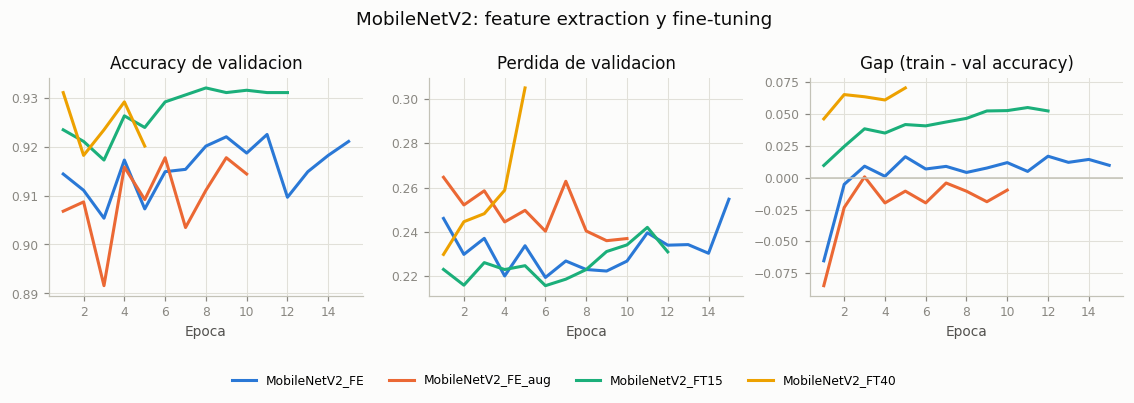


Decision: vigente MobileNetV2_FE (0.9225) | mejor variante MobileNetV2_FT15 (0.9320) | mejora +0.0095 -> SE ADOPTA: MobileNetV2_FT15
Modelo vigente tras la etapa: MobileNetV2_FT15

######################################################################
# ResNet50V2
######################################################################
94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step

=== ResNet50V2_FE | parametros: 23,577,094 (entrenables 12,294) | adam lr=0.001 batch=32
Epoch 1/15
373/373 - 104s - 280ms/step - accuracy: 0.8369 - loss: 0.4575 - val_accuracy: 0.8968 - val_loss: 0.3021
Epoch 2/15
373/373 - 18s - 48ms/step - accuracy: 0.8978 - loss: 0.2806 - val_accuracy: 0.9011 - val_loss: 0.2777
Epoch 3/15
373/373 - 20s - 54ms/step - accuracy: 0.9077 - loss: 0.2465 - val_accuracy: 0.8935 - val_loss: 0.2866
Epoch 4/15
373/373 - 18s - 49ms/step - accuracy: 0.9106 - loss: 0.2372 - val_accuracy: 0.9054 - val_loss: 0.2731
Epoch 5/15
373/373 - 18s - 48ms/step - accuracy: 0.9192 - loss: 0.21

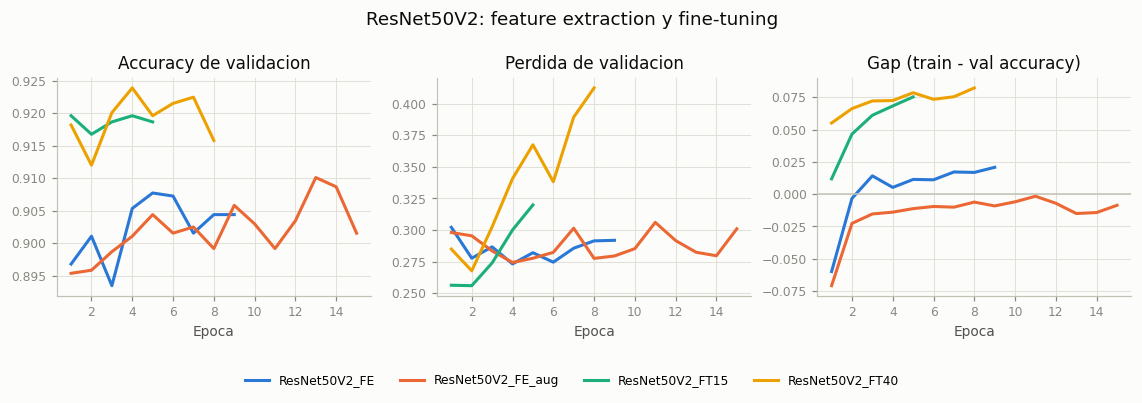


Decision: vigente ResNet50V2_FE (0.9078) | mejor variante ResNet50V2_FT40 (0.9239) | mejora +0.0162 -> SE ADOPTA: ResNet50V2_FT40
Modelo vigente tras la etapa: ResNet50V2_FT40

######################################################################
# Xception
######################################################################
83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step

=== Xception_FE | parametros: 20,873,774 (entrenables 12,294) | adam lr=0.001 batch=32
Epoch 1/15
373/373 - 82s - 221ms/step - accuracy: 0.8576 - loss: 0.4108 - val_accuracy: 0.8987 - val_loss: 0.2793
Epoch 2/15
373/373 - 27s - 73ms/step - accuracy: 0.8964 - loss: 0.2824 - val_accuracy: 0.9020 - val_loss: 0.2592
Epoch 3/15
373/373 - 41s - 111ms/step - accuracy: 0.9066 - loss: 0.2586 - val_accuracy: 0.8916 - val_loss: 0.2681
Epoch 4/15
373/373 - 27s - 73ms/step - accuracy: 0.9104 - loss: 0.2451 - val_accuracy: 0.9068 - val_loss: 0.2515
Epoch 5/15
373/373 - 26s - 70ms/step - accuracy: 0.9127 - loss: 0.2326 - val

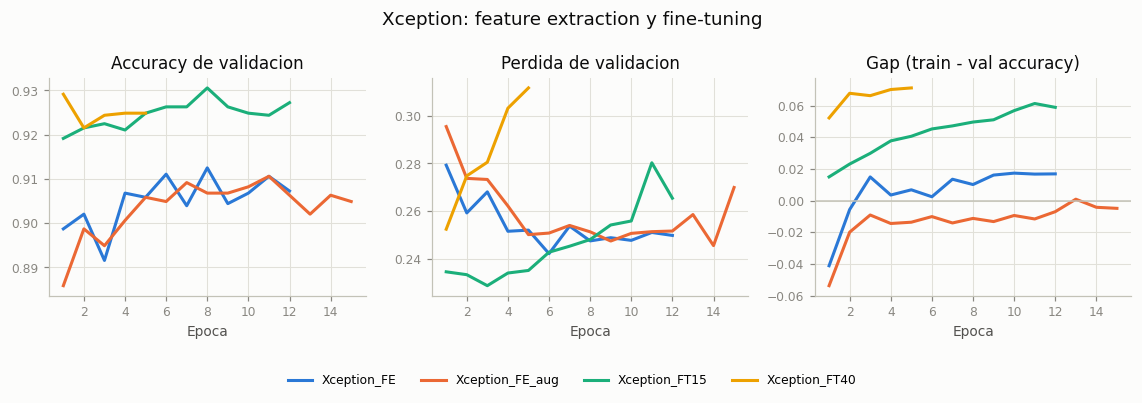


Decision: vigente Xception_FE (0.9125) | mejor variante Xception_FT15 (0.9306) | mejora +0.0181 -> SE ADOPTA: Xception_FT15
Modelo vigente tras la etapa: Xception_FT15


In [28]:
GANADOR_ARQ = {}
FE_ARQ = {}

for arq in ARQUITECTURAS:
    print('\n' + '#' * 70 + f'\n# {arq}\n' + '#' * 70)
    # Fase 1: feature extraction, con y sin data augmentation
    fe = f'{arq}_FE'
    fe_aug = f'{arq}_FE_aug'
    espec = dict(arq=arq, aug=False, drop=0.3, l2_w=0.0, fraccion=0.0,
                 pesos=None, lr=1e-3, epocas=EPOCAS_TL)
    exp_tl(fe, espec)
    exp_tl(fe_aug, {**espec, 'aug': True})
    mejor_fe = decidir(fe, [fe_aug])
    FE_ARQ[arq] = mejor_fe

    # Fase 2: fine-tuning progresivo a partir del mejor modelo congelado
    ft15 = f'{arq}_FT15'
    ft40 = f'{arq}_FT40'
    espec_ft = {**ESPEC[mejor_fe], 'lr': 1e-5, 'epocas': EPOCAS_FT}
    exp_tl(ft15, {**espec_ft, 'fraccion': 0.15, 'pesos': ruta_pesos(mejor_fe)},
           padre=mejor_fe)
    exp_tl(ft40, {**espec_ft, 'fraccion': 0.40, 'pesos': ruta_pesos(ft15)}, padre=ft15)

    nombres = [fe, fe_aug, ft15, ft40]
    print()
    mostrar_tabla(nombres)
    mostrar_curvas(nombres, f'{arq}: feature extraction y fine-tuning')
    GANADOR_ARQ[arq] = decidir(mejor_fe, [ft15, ft40])

**Análisis por arquitectura.**

* **Extracción de características:** Con la base congelada y solo un clasificador nuevo, las tres redes ya superan al mejor modelo desde cero: MobileNetV2 alcanza un 92,3 %, Xception un 91,3 % y ResNet50V2 un 90,8 %, frente al 89,7 %. Lo hacen además en menos épocas y prácticamente sin sobreajuste (gap del 0,5-1,1 %). Las características de ImageNet ya describen bien escenas naturales y urbanas.
* ***Data augmentation*:** No aporta mejora relevante en ninguna arquitectura (-0,48, +0,24 y -0,19 puntos, todos por debajo del umbral), así que se descarta. Con la base congelada no hay sobreajuste que corregir, y el aumento solo dificulta el ajuste del clasificador: la *accuracy* de entrenamiento baja por debajo de la de validación.
* ***Fine-tuning* del 15 % final:** Mejora en las tres redes: +0,95 puntos en MobileNetV2, +1,18 en ResNet50V2 y +1,81 en Xception. Adaptar las capas más específicas a escenas de este dominio aporta información que la base congelada no tenía.
* ***Fine-tuning* del 40 % final:** En MobileNetV2 y Xception no mejora: la mejor época es la primera y después la validación cae, mientras el entrenamiento llega al 98 %. En ResNet50V2 sí aporta (+0,43 puntos), aunque con el gap más alto de todos (7,3 %, entrenamiento al 99,6 %). Al descongelar más capas, el modelo tiene capacidad para memorizar el conjunto, y la ganancia se agota rápidamente.

En las curvas acumuladas, las líneas punteadas marcan el inicio de cada fase de *fine-tuning*. En todos los casos la validación sube nada más comenzar esa fase, pero el entrenamiento se separa enseguida de ella. Es la señal de que con este volumen de datos conviene descongelar de forma limitada.

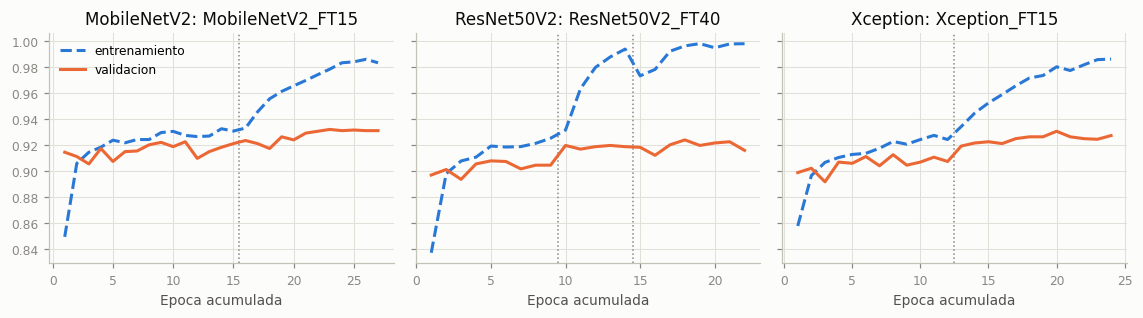

In [29]:
# Evolucion completa de feature extraction a fine-tuning en cada arquitectura
def cadena(nombre):
    pasos = [nombre]
    while RESULTADOS[pasos[0]]['padre']:
        pasos.insert(0, RESULTADOS[pasos[0]]['padre'])
    return pasos


fig, ejes = plt.subplots(1, len(GANADOR_ARQ), figsize=(10.5, 3), sharey=True)
for eje, (arq, ganador) in zip(np.atleast_1d(ejes), GANADOR_ARQ.items()):
    pasos = cadena(ganador)
    tr, va, inicio = [], [], 0
    for n, paso in enumerate(pasos):
        h = RESULTADOS[paso]['historial']
        tr += h['accuracy']
        va += h['val_accuracy']
        if n:
            eje.axvline(inicio + 0.5, color='#898781', linewidth=1, linestyle=':')
        inicio += len(h['accuracy'])
    x = np.arange(1, len(tr) + 1)
    eje.plot(x, tr, color=COLORES[0], linestyle='--', label='entrenamiento')
    eje.plot(x, va, color=COLORES[1], label='validacion')
    eje.set_title(f'{arq}: {ganador}')
    eje.set_xlabel('Epoca acumulada')
np.atleast_1d(ejes)[0].legend()
plt.tight_layout()
plt.show()

### 7.2 Comparación de arquitecturas

In [30]:
ganadores = list(GANADOR_ARQ.values())
mostrar_tabla(ganadores)
MEJOR_ARQ = max(GANADOR_ARQ, key=lambda a: val(GANADOR_ARQ[a]))
print('\nMejor arquitectura en validacion:', MEJOR_ARQ, '->', GANADOR_ARQ[MEJOR_ARQ])

     experimento  val_acc  train_acc    gap  ep_mejor  ep_tot  min  param_k        estado
MobileNetV2_FT15   0.9320     0.9785 0.0465         8      12  2.2     2266 sobreaj. leve
 ResNet50V2_FT40   0.9239     0.9964 0.0725         4       8  5.2    23577 sobreaj. leve
   Xception_FT15   0.9306     0.9803 0.0497         8      12  7.3    20874 sobreaj. leve

Mejor arquitectura en validacion: MobileNetV2 -> MobileNetV2_FT15


**Comparación de arquitecturas.**

| Arquitectura | Val. acc. | Parámetros | Tiempo de entrenamiento |
|---|---|---|---|
| MobileNetV2 | **93,2 %** | 2,3 M | 5,0 min |
| Xception | 93,1 % | 20,9 M | 13,9 min |
| ResNet50V2 | 92,4 % | 23,6 M | 11,9 min |

La diferencia de *accuracy* entre arquitecturas es inferior a un punto, en el orden del ruido entre ejecuciones. MobileNetV2, que es la más ligera (9-10 veces menos parámetros que las otras) y la más rápida de entrenar, iguala o supera a redes mucho mayores. Las imágenes de entrada son pequeñas (160x160) y el problema solo tiene 6 clases, así que la capacidad adicional de ResNet50V2 y Xception no se traduce en mejor generalización, y en ResNet50V2 sí aumenta el sobreajuste. **Se selecciona MobileNetV2**, que ofrece el mejor equilibrio entre precisión y coste.

### 7.3 Ajuste final de la mejor arquitectura

Sobre la arquitectura ganadora se estudian dos variaciones de *fine-tuning*: una tasa de aprendizaje diez veces mayor y una regularización más fuerte del clasificador (*dropout* 0,5 y L2).


=== MobileNetV2_aj_lr1e-4 | parametros: 2,265,670 (entrenables 1,356,166) | adam lr=0.0001 batch=32
Epoch 1/15
373/373 - 31s - 83ms/step - accuracy: 0.9060 - loss: 0.2577 - val_accuracy: 0.9182 - val_loss: 0.2424
Epoch 2/15
373/373 - 9s - 23ms/step - accuracy: 0.9290 - loss: 0.1875 - val_accuracy: 0.9001 - val_loss: 0.2860
Epoch 3/15
373/373 - 9s - 23ms/step - accuracy: 0.9499 - loss: 0.1365 - val_accuracy: 0.8997 - val_loss: 0.2573
Epoch 4/15
373/373 - 9s - 24ms/step - accuracy: 0.9602 - loss: 0.1106 - val_accuracy: 0.9306 - val_loss: 0.2161
Epoch 5/15
373/373 - 9s - 23ms/step - accuracy: 0.9673 - loss: 0.0845 - val_accuracy: 0.9196 - val_loss: 0.2732
Epoch 6/15
373/373 - 9s - 24ms/step - accuracy: 0.9711 - loss: 0.0752 - val_accuracy: 0.9215 - val_loss: 0.2642
Epoch 7/15
373/373 - 8s - 23ms/step - accuracy: 0.9755 - loss: 0.0673 - val_accuracy: 0.9144 - val_loss: 0.2573
Epoch 8/15
373/373 - 8s - 22ms/step - accuracy: 0.9782 - loss: 0.0545 - val_accuracy: 0.9301 - val_loss: 0.2978

=

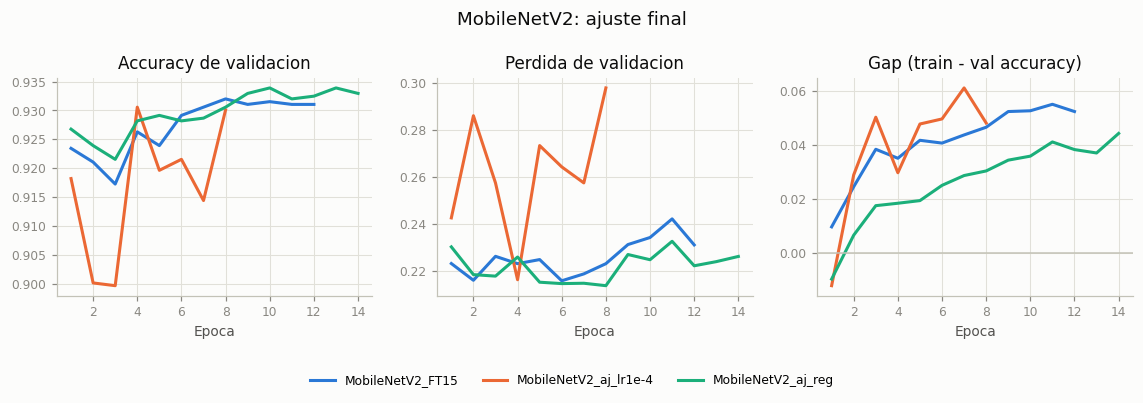


Decision: vigente MobileNetV2_FT15 (0.9320) | mejor variante MobileNetV2_aj_reg (0.9339) | mejora +0.0019 -> SE MANTIENE EL VIGENTE; descartado: MobileNetV2_aj_reg
Modelo vigente tras la etapa: MobileNetV2_FT15

Modelo seleccionado para la estrategia 2: MobileNetV2_FT15


In [31]:
actual_tl = GANADOR_ARQ[MEJOR_ARQ]
fe_base = FE_ARQ[MEJOR_ARQ]
frac = ESPEC[actual_tl]['fraccion'] or 0.15
espec_aj = {**ESPEC[fe_base], 'fraccion': frac, 'pesos': ruta_pesos(fe_base),
            'lr': 1e-5, 'epocas': EPOCAS_FT}

aj_lr = f'{MEJOR_ARQ}_aj_lr1e-4'
aj_reg = f'{MEJOR_ARQ}_aj_reg'
exp_tl(aj_lr, {**espec_aj, 'lr': 1e-4}, padre=fe_base)
exp_tl(aj_reg, {**espec_aj, 'drop': 0.5, 'l2_w': 1e-4}, padre=fe_base)

nombres = [actual_tl, aj_lr, aj_reg]
print()
mostrar_tabla(nombres)
mostrar_curvas(nombres, f'{MEJOR_ARQ}: ajuste final')
MEJOR_TL = decidir(actual_tl, [aj_lr, aj_reg])
GANADOR_ARQ[MEJOR_ARQ] = MEJOR_TL
print('\nModelo seleccionado para la estrategia 2:', MEJOR_TL)

**Análisis del ajuste final:** Ninguna variación supera el umbral de mejora:

* **Tasa de aprendizaje de 1e-4:** converge en menos épocas (mejor época 4), pero se queda en un 93,1 %, porque una tasa 10 veces mayor modifica los pesos preentrenados con más agresividad.
* **Más regularización del clasificador (*dropout* 0,5 y L2):** reduce el gap del 4,7 % al 3,6 % y obtiene un 93,4 %. La mejora de +0,19 puntos queda por debajo del umbral de 0,3 puntos, así que no es distinguible del ruido.

Se mantiene **MobileNetV2_FT15**: base de MobileNetV2 con el 15 % final descongelado, *fine-tuning* con Adam a 1e-5, *dropout* de 0,3 y sin *data augmentation*. El *fine-tuning* moderado ya estaba bien ajustado, y el margen restante es pequeño.

## 8. Evaluación final sobre test y comparación

Hasta este punto todas las decisiones se han tomado con validación. El conjunto de test se usa ahora **una sola vez** sobre los modelos ya fijados. Se incluyen:

* Un clasificador trivial, como referencia mínima.
* El modelo base y el modelo final desde cero.
* El mejor modelo de cada arquitectura preentrenada.

In [32]:
def reconstruir(nombre):
    espec = ESPEC[nombre]
    if RESULTADOS[nombre]['estrategia'] == 'scratch':
        cfg = {k: v for k, v in espec.items() if k not in CLAVES_ENT}
        modelo = construir_cnn(**cfg)
    else:
        cfg = {k: espec[k] for k in CLAVES_TL}
        cfg['pesos'] = None
        modelo = construir_tl(**cfg)
    modelo.load_weights(ruta_pesos(nombre))
    return modelo


def tiempo_total(nombre):
    return sum(RESULTADOS[p]['tiempo_s'] for p in cadena(nombre))


def wilson(aciertos, n, z=1.96):
    p = aciertos / n
    d = 1 + z ** 2 / n
    centro = (p + z ** 2 / (2 * n)) / d
    margen = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return centro - margen, centro + margen


MODELOS_TEST = {'CNN base': 'F0_base', 'CNN final': MEJOR_SCRATCH}
MODELOS_TEST.update(GANADOR_ARQ)

trivial = DummyClassifier(strategy='most_frequent').fit(df_tr[['y']], df_tr['y'])
acc_trivial = accuracy_score(y_test, trivial.predict(df_test[['y']]))
print(f'Clasificador trivial (clase mayoritaria): accuracy test = {acc_trivial:.4f}')
print(f'Prediccion aleatoria uniforme esperada:   {1 / NUM_CLASES:.4f}')

PRED = {}
filas = []
for etiqueta, nombre in MODELOS_TEST.items():
    keras.backend.clear_session()
    modelo = reconstruir(nombre)
    t0 = time.time()
    proba = modelo.predict(lote('test'), verbose=0)
    ms_img = 1000 * (time.time() - t0) / len(y_test)
    pred = proba.argmax(axis=1)
    PRED[etiqueta] = pred
    acc = accuracy_score(y_test, pred)
    inf, sup = wilson(int((pred == y_test).sum()), len(y_test))
    filas.append({'modelo': etiqueta, 'test_acc': acc, 'ic95_inf': inf, 'ic95_sup': sup,
                  'f1_macro': f1_score(y_test, pred, average='macro'),
                  'val_acc': val(nombre), 'val-test': val(nombre) - acc,
                  'train_min': tiempo_total(nombre) / 60, 'ms_img': ms_img,
                  'param_M': modelo.count_params() / 1e6})
    del modelo

tabla_test = pd.DataFrame(filas)
print()
print(tabla_test.round(4).to_string(index=False))

Clasificador trivial (clase mayoritaria): accuracy test = 0.1750
Prediccion aleatoria uniforme esperada:   0.1667

     modelo  test_acc  ic95_inf  ic95_sup  f1_macro  val_acc  val-test  train_min  ms_img  param_M
   CNN base    0.8080    0.7935    0.8217    0.8072   0.8274    0.0194     3.3643  1.5390   5.4026
  CNN final    0.8857    0.8738    0.8966    0.8871   0.8973    0.0116     7.5786  1.1160   0.4221
MobileNetV2    0.9253    0.9154    0.9342    0.9268   0.9320    0.0067     5.0076  6.9919   2.2657
 ResNet50V2    0.9180    0.9076    0.9273    0.9199   0.9239    0.0059    11.8607 13.6612  23.5771
   Xception    0.9217    0.9115    0.9308    0.9234   0.9306    0.0089    13.8596  7.6856  20.8738


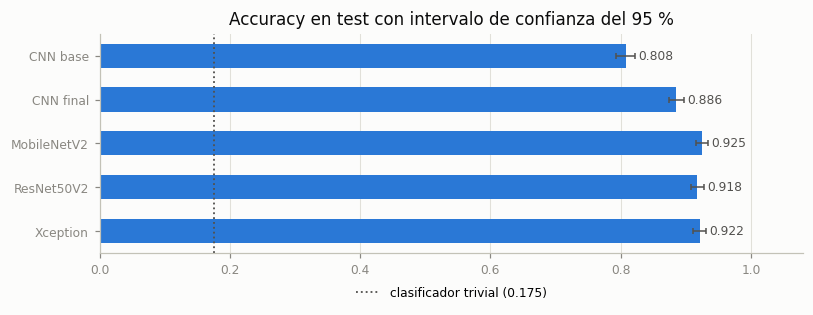

In [33]:
fig, eje = plt.subplots(figsize=(7.5, 3))
orden = tabla_test.iloc[::-1]
posiciones = np.arange(len(orden))
error = [orden['test_acc'] - orden['ic95_inf'], orden['ic95_sup'] - orden['test_acc']]
eje.barh(posiciones, orden['test_acc'], xerr=error, color=COLORES[0], height=0.55,
         error_kw={'ecolor': '#52514e', 'elinewidth': 1, 'capsize': 2})
eje.set_yticks(posiciones, orden['modelo'])
for y, v, s in zip(posiciones, orden['test_acc'], orden['ic95_sup']):
    eje.text(s + 0.005, y, f'{v:.3f}', va='center', fontsize=8, color='#52514e')
eje.axvline(acc_trivial, color='#52514e', linestyle=':', linewidth=1.2,
            label=f'clasificador trivial ({acc_trivial:.3f})')
eje.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1))
eje.set_xlim(0, 1.08)
eje.grid(axis='y', visible=False)
eje.set_title('Accuracy en test con intervalo de confianza del 95 %')
plt.tight_layout()
plt.show()

=== CNN desde cero (F5_adam_rlrop) ===
              precision    recall  f1-score   support

   buildings      0.875     0.879     0.877       437
      forest      0.971     0.985     0.978       474
     glacier      0.867     0.790     0.827       553
    mountain      0.824     0.846     0.835       525
         sea      0.881     0.939     0.909       510
      street      0.905     0.890     0.897       501

    accuracy                          0.886      3000
   macro avg      0.887     0.888     0.887      3000
weighted avg      0.886     0.886     0.885      3000

=== Preentrenada (MobileNetV2_FT15) ===
              precision    recall  f1-score   support

   buildings      0.929     0.922     0.925       437
      forest      0.985     0.985     0.985       474
     glacier      0.881     0.866     0.873       553
    mountain      0.887     0.878     0.882       525
         sea      0.957     0.971     0.964       510
      street      0.922     0.940     0.931       501

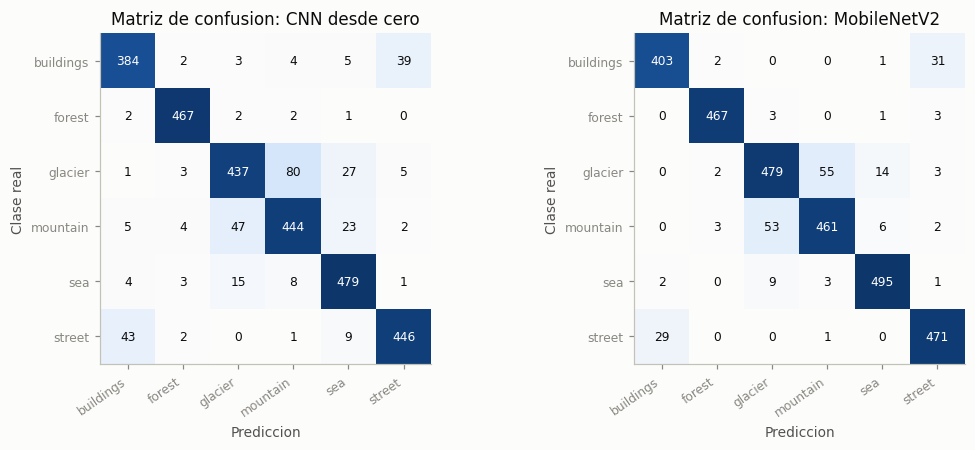

In [34]:
# Comparacion directa entre las dos estrategias
ET_TL = next(a for a, n in GANADOR_ARQ.items() if n == MEJOR_TL)
p_cnn, p_tl = PRED['CNN final'], PRED[ET_TL]

print(f'=== CNN desde cero ({MEJOR_SCRATCH}) ===')
print(classification_report(y_test, p_cnn, target_names=CLASES, digits=3, zero_division=0))
print(f'=== Preentrenada ({MEJOR_TL}) ===')
print(classification_report(y_test, p_tl, target_names=CLASES, digits=3, zero_division=0))

fig, ejes = plt.subplots(1, 2, figsize=(10, 4.2))
for eje, pred, titulo in zip(ejes, [p_cnn, p_tl], ['CNN desde cero', ET_TL]):
    mc = confusion_matrix(y_test, pred, labels=range(NUM_CLASES))
    eje.imshow(mc, cmap=AZULES, vmin=0, vmax=mc.max())
    eje.set_xticks(range(NUM_CLASES), CLASES, rotation=35, ha='right')
    eje.set_yticks(range(NUM_CLASES), CLASES)
    eje.grid(False)
    eje.set_xlabel('Prediccion')
    eje.set_ylabel('Clase real')
    eje.set_title(f'Matriz de confusion: {titulo}')
    for i in range(NUM_CLASES):
        for j in range(NUM_CLASES):
            color = '#ffffff' if mc[i, j] > 0.55 * mc.max() else '#0b0b0b'
            eje.text(j, i, mc[i, j], ha='center', va='center', fontsize=8, color=color)
plt.tight_layout()
plt.show()

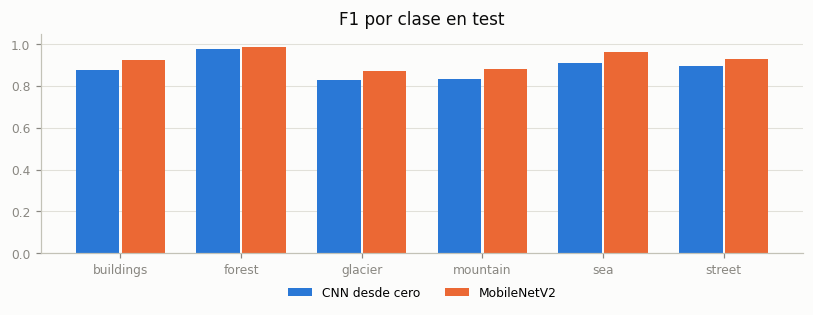

Aciertos solo de la CNN: 93 | solo de la preentrenada: 212
Prueba exacta de McNemar: p = 7.706e-12


In [35]:
# F1 por clase y prueba de McNemar sobre las predicciones emparejadas
f1_cnn = f1_score(y_test, p_cnn, average=None, labels=range(NUM_CLASES), zero_division=0)
f1_tl = f1_score(y_test, p_tl, average=None, labels=range(NUM_CLASES), zero_division=0)

x = np.arange(NUM_CLASES)
fig, eje = plt.subplots(figsize=(7.5, 3))
eje.bar(x - 0.19, f1_cnn, width=0.36, color=COLORES[0], label='CNN desde cero')
eje.bar(x + 0.19, f1_tl, width=0.36, color=COLORES[1], label=ET_TL)
eje.set_xticks(x, CLASES)
eje.set_ylim(0, 1.05)
eje.grid(axis='x', visible=False)
eje.set_title('F1 por clase en test')
eje.legend(ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.1))
plt.tight_layout()
plt.show()

solo_cnn = int(((p_cnn == y_test) & (p_tl != y_test)).sum())
solo_tl = int(((p_tl == y_test) & (p_cnn != y_test)).sum())
discordantes = solo_cnn + solo_tl
p_valor = binomtest(solo_cnn, discordantes, 0.5).pvalue if discordantes else 1.0
print(f'Aciertos solo de la CNN: {solo_cnn} | solo de la preentrenada: {solo_tl}')
print(f'Prueba exacta de McNemar: p = {p_valor:.4g}')

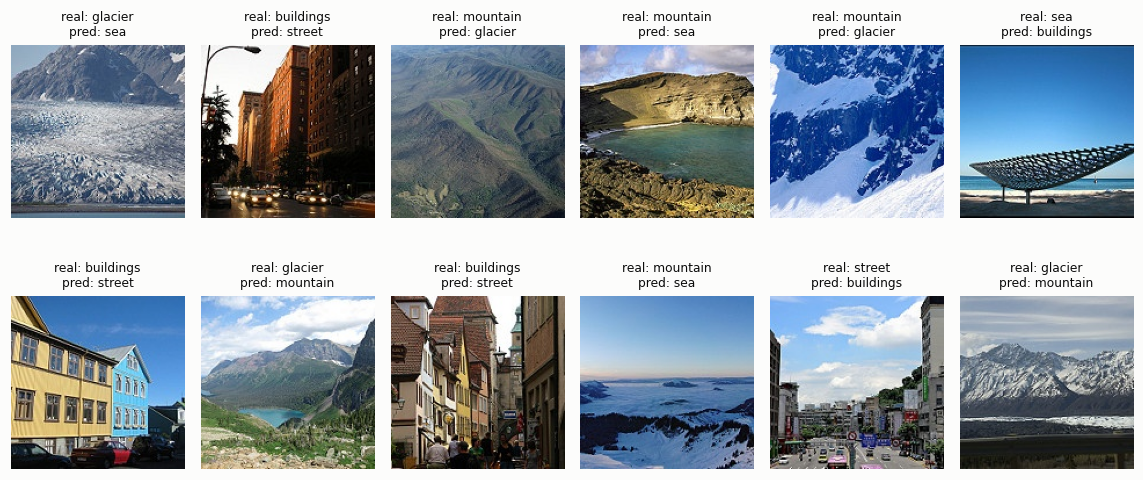

In [36]:
# Ejemplos que el mejor modelo preentrenado clasifica mal
errores = np.where(p_tl != y_test)[0]
rng = np.random.default_rng(SEED)
elegidos = rng.choice(errores, min(12, len(errores)), replace=False)
fig, ejes = plt.subplots(2, 6, figsize=(10.5, 5))
for eje in ejes.ravel():
    eje.axis('off')
for eje, i in zip(ejes.ravel(), elegidos):
    eje.imshow(Image.open(df_test.loc[i, 'ruta']).convert('RGB'))
    eje.set_title(f'real: {CLASES[y_test[i]]}\npred: {CLASES[p_tl[i]]}', fontsize=8)
plt.tight_layout()
plt.show()

### Análisis de los resultados en test

**Rendimiento:** Todos los modelos superan con claridad la referencia trivial (17,5 %), así que han aprendido patrones reales:

| Modelo | *Accuracy* en test | Intervalo de confianza del 95 % | F1 *macro* |
|---|---|---|---|
| CNN base | 80,8 % | - | - |
| CNN final | 88,6 % | 87,4 %-89,7 % | 0,887 |
| **MobileNetV2** | **92,5 %** | 91,5 %-93,4 % | 0,927 |
| Xception | 92,2 % | - | - |
| ResNet50V2 | 91,8 % | - | - |

**Significación:** Los intervalos de confianza de la CNN final y MobileNetV2 no se solapan. La prueba de McNemar sobre las mismas 3.000 imágenes es contundente: MobileNetV2 acierta 212 imágenes que la CNN falla, frente a 93 en sentido contrario (p = 7,7e-12). La superioridad del *transfer learning* es estadísticamente significativa. En cambio, las tres redes preentrenadas tienen intervalos solapados, así que sus diferencias en test no son concluyentes.

**Generalización:** La diferencia entre validación y test es pequeña en todos los modelos (0,6-1,9 puntos). Por tanto, la selección mediante validación no ha sobreajustado ese conjunto y las estimaciones son fiables. La CNN base es la que más se degrada (1,9 puntos), coherente con su fuerte sobreajuste.

**Errores por clase:** Ambos modelos fallan en los mismos pares de clases, aunque MobileNetV2 lo hace en menor medida:

* ***glacier* y *mountain*:** es la confusión dominante. La CNN etiqueta 80 glaciares como montañas y 47 montañas como glaciares; MobileNetV2, 55 y 53. Son las clases con menor F1 (0,83 y 0,84 en la CNN; 0,87 y 0,88 en MobileNetV2).
* ***buildings* y *street*:** la CNN confunde 39 y 43 imágenes; MobileNetV2, 31 y 29.
* ***sea*:** la CNN confunde con mar 27 glaciares y 23 montañas (horizontes, agua y nieve). MobileNetV2 casi lo resuelve: F1 de 0,964 frente a 0,909.
* ***forest*:** es la clase más fácil para ambos modelos (F1 de 0,98).

**¿Errores del modelo o de las etiquetas?** En los ejemplos mal clasificados, muchos errores son **ambigüedades del propio conjunto**. Hay montañas nevadas etiquetadas como *glacier*, glaciares con montañas al fondo y calles cuyo contenido principal son fachadas. Junto con las 10 imágenes duplicadas con etiquetas distintas detectadas en la sección 3, esto indica que parte del error residual no es atribuible al modelo y que alcanzar el 100 % no es realista en este conjunto.

## 9. Conclusiones

1. **Rendimiento:** Ambas estrategias resuelven el problema con claridad frente a la referencia trivial (17,5 % en test). La mejor CNN desde cero alcanza un **88,6 %** de *accuracy* en test (F1 *macro* de 0,887). La mejor red preentrenada, **MobileNetV2 con *fine-tuning* del 15 % final, alcanza un 92,5 %** (F1 *macro* de 0,927). La diferencia es de 3,96 puntos y es estadísticamente significativa (McNemar, p < 1e-11).

2. **Entrenamiento y generalización:** La CNN desde cero partió de un sobreajuste severo (gap del 15,6 %, pérdida de validación creciente desde la época 3). Lo corrigieron sobre todo la reducción de capacidad (cuarto bloque y *Global Average Pooling*) y el *dropout*, hasta un gap del 3,4 %. Las redes preentrenadas apenas sobreajustan en extracción de características, y el *fine-tuning* moderado mejora la validación con un sobreajuste controlado. En ambos casos la diferencia entre validación y test es inferior a 2 puntos, lo que indica buena generalización y una selección de modelos fiable.

3. **Sobreajuste y regularización:** El sobreajuste fue el problema dominante de la CNN desde cero. GAP y *dropout* fueron las soluciones más eficaces. L2 provocó un leve subajuste, *batch normalization* desestabilizó la validación y *data augmentation* eliminó el gap sin mejorar la validación en el número de épocas disponible. En *transfer learning*, el riesgo aparece al descongelar demasiadas capas: con el 40 %, el entrenamiento llega al 98-99,6 % sin ganancia en validación en dos de las tres redes.

4. **Ventajas e inconvenientes:**

| | CNN desde cero | *Transfer learning* (MobileNetV2) |
|---|---|---|
| *Accuracy* en test | 88,6 % | **92,5 %** |
| Parámetros | **0,42 M** | 2,27 M |
| Inferencia | **1,1 ms por imagen** | 7,0 ms por imagen |
| Entrenamiento del modelo final | 7,6 min | **5,0 min** |
| Coste de experimentación | 17 entrenamientos (unos 90 min) | 6 entrenamientos (unos 13 min) |
| Dependencias | Ninguna | Pesos de ImageNet |

La CNN propia es 5 veces más pequeña y unas 6 veces más rápida en inferencia, lo que la hace preferible en dispositivos con recursos muy limitados si se acepta perder unos 4 puntos de precisión. Además, aporta un control total de la arquitectura. Su gran inconveniente es el coste del diseño: fueron necesarios muchos experimentos para corregir el sobreajuste. La estrategia preentrenada logra más precisión con menos entrenamiento y menos ajuste de hiperparámetros, porque parte de características generales ya aprendidas sobre millones de imágenes.

5. **Estrategia recomendada:** Para este problema, la mejor solución es el **transfer learning con fine-tuning moderado de MobileNetV2**. Las escenas naturales y urbanas se parecen mucho a las imágenes de ImageNet, por lo que bordes, texturas y formas aprendidos allí son directamente reutilizables. Aunque unas 12.000 imágenes permiten entrenar una CNN razonable desde cero, no bastan para aprender representaciones tan ricas como las preentrenadas. Entre las arquitecturas preentrenadas, las diferencias de precisión no son significativas, así que MobileNetV2 es la elección más eficiente: iguala a Xception y ResNet50V2 con 9-10 veces menos parámetros y la mitad o menos de tiempo de entrenamiento.

**Límites del estudio y posibles mejoras:** Cada configuración se entrenó con una sola semilla, por lo que las diferencias inferiores a 0,5 puntos deben interpretarse con cautela. Además, la paciencia de la parada temprana pudo penalizar las variantes que convergen más despacio (L2, *data augmentation*, SGD). Como trabajo futuro se propone evaluar varias semillas, combinar *dropout* y *data augmentation* con más épocas, y revisar las imágenes con etiquetas ambiguas entre *glacier* y *mountain*.